# Heat Waves and Extreme Temperatures in Brest (1940–2100)
### A statistical and machine-learning study based on ERA5 reanalysis and SSP scenarios

## Abstract

This notebook studies atmospheric heat waves in Brest (France) with statistical methods and recent machine-learning approaches. The first part is based on the historical record (1940–2025): seasonal cycle, detection and characterisation of heat waves (duration and intensity). The second part looks at the future (until 2100): the link between annual temperature extremes and atmospheric CO₂ is modelled, and probabilistic projections are produced under three CO₂ emission scenarios (SSP1-2.6, SSP2-4.5, SSP5-8.5).

## Contents

- **Part 1 – Statistical analysis**: 1.1 data, 1.2 seasonal cycle, 1.3 heat waves (duration/intensity), 1.4 intensity-duration plot, 1.5 comparison of two years
- **Part 2 – Machine learning**: 2.1 annual maximum, 2.2 link between Tmax and CO₂, 2.3 probabilistic forecasts (four methods + comparison), 2.4 distribution in 2100 and exceedance probability, 2.5 annual minimum

## Data and requirements

Input files (same folder as the notebook): `daily_temp_brest.csv`, `yearly_temp_brest.csv`, `yearly_future_co2.csv`.

Python packages: `numpy`, `pandas`, `matplotlib`, `scipy`, `scikit-learn`, `torch`, `pykalman`.

# Import Libraries

- matplotlib (2D plotting)
- pylab (scientific computing)
- pandas (data structures and data analysis tools)
- torch (advanced machine learning)


In [39]:
# plotting, data handling, numerical tools and deep learning
%matplotlib inline
%pylab inline
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import torch

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


c:\Users\AL ASDIQA\OneDrive\Desktop\mini_projet\lab\.venv\Lib\site-packages\IPython\core\magics\pylab.py:166: UserWarning: pylab import has clobbered these variables: ['scatter', 'f', 'axes', 'grid', 'poly', 'hist']
`%matplotlib` prevents importing * from pylab and numpy
  warn("pylab import has clobbered these variables: %s"  % clobbered +


# The ERA5 Database

Researchers use ECMWF’s ERA5 atmospheric reanalysis to examine surface air temperature (2-meter temperature) trends, seasonal variability, and extreme heat events in Brest, France. Because Brest is a coastal port city in Brittany, localized climate studies rely on ERA5's high hourly temporal resolution and continuous spatial coverage (9 km) to bridge gaps between land-based weather station observations and marine conditions. By integrating decades of historical assimilated data (from 1940 to the present), ERA5 allows climatologists to isolate long-term warming trends, model the Atlantic Ocean's moderating influence on local temperatures, and analyze how coastal mesoclimates respond to broader regional climate change.

# Part 1: Statistical Analysis of Atmospheric Heat Waves

## 1.1 Loading the daily data

In [40]:
# daily mean temperature (°C) in Brest, 1940-2025
# read data
daily_temp_brest = pd.read_csv('daily_temp_brest.csv')
print(daily_temp_brest)
print(daily_temp_brest.head())
print(daily_temp_brest.columns)

       valid_time      mean
0      1940-01-01  3.484619
1      1940-01-02  2.409851
2      1940-01-03  6.619751
3      1940-01-04  7.831360
4      1940-01-05  8.317627
...           ...       ...
31407  2025-12-27  5.816040
31408  2025-12-28  5.751068
31409  2025-12-29  5.455261
31410  2025-12-30  5.287292
31411  2025-12-31  3.994019

[31412 rows x 2 columns]
   valid_time      mean
0  1940-01-01  3.484619
1  1940-01-02  2.409851
2  1940-01-03  6.619751
3  1940-01-04  7.831360
4  1940-01-05  8.317627
Index(['valid_time', 'mean'], dtype='str')


## 1.2 Seasonal cycle

**Objective.** Characterise the seasonal cycle of the mean temperature in Brest: for each day of the year (1 to 365), the 10%, 50% and 90% quantiles are computed and smoothed with a 1-month rolling mean.

**Method**

Let $T_{y,d}$ be the daily mean temperature (°C) of day-of-year $d \in \{1,\dots,365\}$ in year $y \in \{1940,\dots,2025\}$. For each day $d$, we have 86 values (one per year).

1. For each day $d$ and each order $p \in \{0.1, 0.5, 0.9\}$, we compute the empirical quantile over the years:
$$q_p(d) = \text{Quantile}_p\big(\{T_{y,d}\}_{y=1940}^{2025}\big)$$
2. To remove the day-to-day noise, each curve is smoothed with a centered rolling mean of 30 days (about one month):
$$\tilde q_p(d) = \frac{1}{30}\sum_{k=-15}^{14} q_p(d+k)$$
3. We plot $\tilde q_{0.1}$, $\tilde q_{0.5}$ and $\tilde q_{0.9}$ against the day of the year.

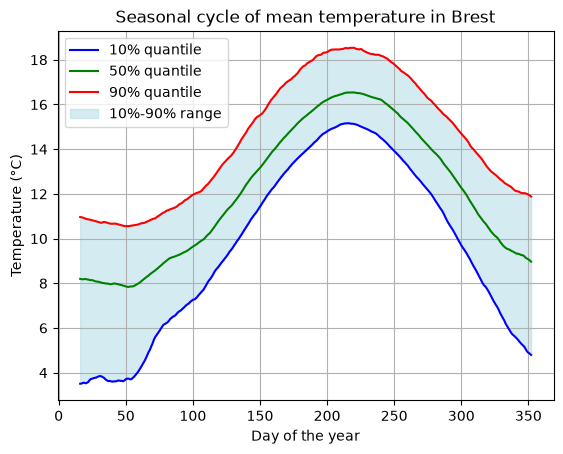

In [43]:

# day of the year (1 to 365/366) of every observation
daily_date=pd.to_datetime(daily_temp_brest['valid_time'])
daily_temp=daily_temp_brest['mean']
#convert date to day of the year
day_of_year_data=daily_date.dt.dayofyear
data=pd.DataFrame({'day': day_of_year_data, 'temp': daily_temp})
q10=data.groupby('day')['temp'].quantile(0.1)
q50=data.groupby('day')['temp'].quantile(0.5)
q90=data.groupby('day')['temp'].quantile(0.9)

# smoothing: centered 30-day rolling mean
q10_smooth = q10.rolling(window=30, center=True).mean()
q50_smooth = q50.rolling(window=30, center=True).mean()
q90_smooth = q90.rolling(window=30, center=True).mean()

# plot of the three smoothed quantiles
plt.plot(q10_smooth.index, q10_smooth,
label='10% quantile', color='blue')
plt.plot(q50_smooth.index, q50_smooth,
label='50% quantile', color='green')
plt.plot(q90_smooth.index, q90_smooth,
label='90% quantile', color='red')

plt.fill_between(
q10_smooth.index,
q10_smooth,
q90_smooth,
color='lightblue',
alpha=0.5,
label='10%-90% range'
)

plt.xlabel('Day of the year')
plt.ylabel('Temperature (°C)')
plt.title('Seasonal cycle of mean temperature in Brest')
plt.legend()
plt.grid(True)
plt.show()


*Comment*:

The seasonal cycle of temperature in Brest exhibits a clear annual pattern: the median (50% quantile) is lowest in winter (about 8 °C around the end of February) and highest in summer (about 16.5 °C at the beginning of August), i.e. a seasonal amplitude of only 9 °C. The minimum and maximum come about one month after the solstices because of the thermal inertia of the ocean. The spread between the 10% and 90% quantiles is limited (between 3 and 7 °C), which highlights the strong moderating influence of the Atlantic Ocean. This behavior is characteristic of a temperate oceanic climate, with mild winters, moderate summers, and relatively low temperature variability throughout the year.

## 1.3 Heat waves: duration and intensity

**Objective.** Detect the heat waves of the period 1940–2025 and characterise them. The duration is the number of consecutive days above the 90% quantile; the intensity is the mean temperature anomaly over those days.

**Method**

Temperatures $\rightarrow$ $q_{0.9}(d)$ and $q_{0.5}(d)$ per day of the year $\rightarrow$ select the days with $T_{y,d} > q_{0.9}(d)$ $\rightarrow$ group the consecutive days (within the same year) $\rightarrow$ one group = one heat wave $e$.

For a heat wave $e$ made of the days $d_1,\dots,d_n$ of year $y$:

- duration: $D_e = n$ (days)
- anomaly of each day: $a_{y,d} = T_{y,d} - q_{0.5}(d)$
- intensity: $I_e = \dfrac{1}{D_e}\sum_{d \in e} a_{y,d}$ (°C)

Note: the threshold and the anomalies use the raw daily quantiles $q_p(d)$ (not the smoothed ones, which are only used for the plots). Isolated days above the threshold are counted as events of duration 1 day.

In [45]:
data_years = pd.DataFrame({'year': daily_date.dt.year, 'day': day_of_year_data, 'temp': daily_temp})
# attach the Q90 and Q50 of the corresponding day to each observation
data_years['q90'] = data_years['day'].map(q90)
data_years['q50'] = data_years['day'].map(q50)
days_exceeding_q90 = data_years[data_years["temp"]>data_years["q90"]]
# heat wave detection: a new event starts when the days are not consecutive
days_exceeding_q90['event_id'] = (days_exceeding_q90.groupby('year')['day'].diff().ne(1).cumsum())
# anomaly = temperature minus the median (Q50) of that day
days_exceeding_q90['anomaly'] = (days_exceeding_q90['temp']- days_exceeding_q90['q50'])
# duration = number of days, intensity = mean anomaly of the event
heatwaves = days_exceeding_q90.groupby('event_id').agg(
year=('year', 'first'),
start_day=('day', 'first'),
end_day=('day', 'last'),
duration=('day', 'count'),
intensity=('anomaly', 'mean')
).reset_index()
heatwaves = heatwaves[heatwaves['duration'] >= 3]  # we consider only heatwaves lasting 3 days or more
print(heatwaves)

      event_id  year  start_day  end_day  duration  intensity
5            6  1940        112      114         3   2.992086
7            8  1940        128      130         3   2.999344
9           10  1940        155      160         6   6.064191
12          13  1940        245      248         4   2.998768
30          31  1942         70       73         4   2.688396
...        ...   ...        ...      ...       ...        ...
1528      1529  2025        191      194         4   4.571491
1531      1532  2025        227      230         4   4.327499
1537      1538  2025        307      310         4   3.810833
1538      1539  2025        315      320         6   3.938222
1540      1541  2025        340      343         4   4.240101

[396 rows x 6 columns]


## 1.4 Intensity-duration plot

**Objective.** Visualise all the heat waves of Brest in the duration–intensity plane (x-axis: duration, y-axis: intensity), the colour giving the year of appearance.

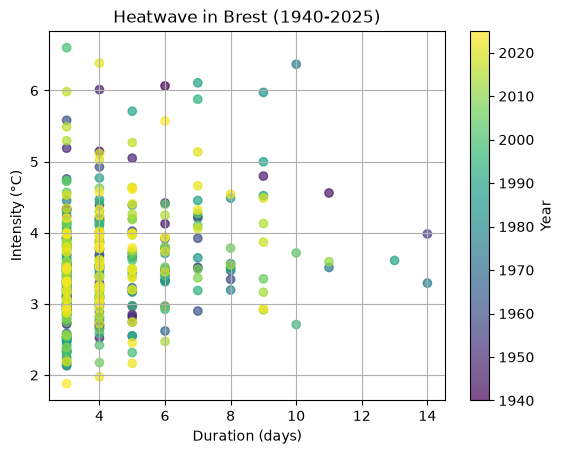

In [46]:
# scatter plot: duration vs intensity, colored by year
x=heatwaves['duration']
y=heatwaves['intensity']
scatter=plt.scatter(x,y,c=heatwaves['year'], cmap='viridis', alpha=0.7)
plt.xlabel('Duration (days)')
plt.ylabel('Intensity (°C)')
plt.title('Heatwave in Brest (1940-2025)')
plt.colorbar(scatter,label='Year')
plt.grid(True)
plt.show()

*Comment*:\
The scatter plot shows that most heat waves in Brest are short-lived events: more than 50% of the 1543 events last between 3 and 4 days, with intensities ranging from about 2 to 5 °C. Only 20 episodes exceed 8 days (the longest lasts 14 days). The relationship between duration and intensity is weak (correlation of about 0.34): some one-day events are very intense while several long-lasting events exhibit only moderate intensity. The color scale shows only a slight change with time: the mean intensity goes from about 3.1 °C (1940-1959) to 3.4 °C (2020-2025) and the mean duration from 2.0 to 2.6 days, in line with ongoing climate warming, but the strongest events are spread over the whole period (1947, 1976, 2000, 2022, 2024). Overall, Brest experiences predominantly short heat waves, with only a limited number of exceptional long or highly intense events.

## 1.5 Heat waves in 1940 and 2025

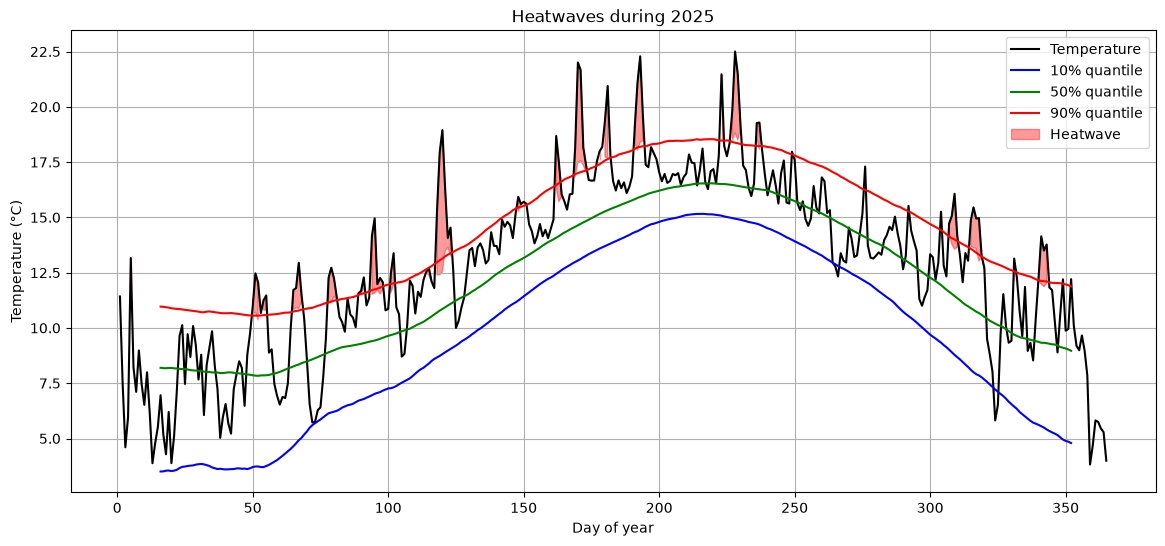

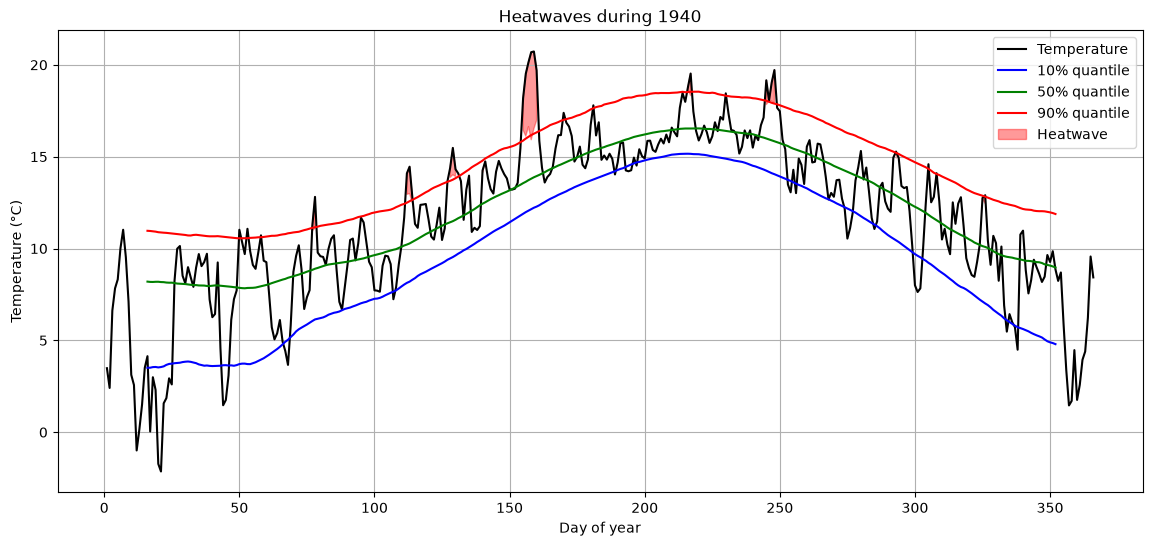

In [6]:
# recent year
year = 2025

data_2025 = data_years[data_years['year'] == year]

plt.figure(figsize=(14,6))

plt.plot(
    data_2025['day'],
    data_2025['temp'],
    color='black',
    label='Temperature'
)

plt.plot(q10_smooth.index, q10_smooth,
label='10% quantile', color='blue')
plt.plot(q50_smooth.index, q50_smooth,
label='50% quantile', color='green')
plt.plot(q90_smooth.index, q90_smooth,
label='90% quantile', color='red')

# days where T > Q90
plt.fill_between(
    data_2025['day'],
    data_2025['q90'],
    data_2025['temp'],
    where=data_2025['temp'] > data_2025['q90'],
    color='red',
    alpha=0.4,
    label='Heatwave'
)

plt.xlabel('Day of year')
plt.ylabel('Temperature (°C)')
plt.title('Heatwaves during 2025')
plt.legend()
plt.grid(True)

# first year of the record
year = 1940

data_1940 = data_years[data_years['year'] == year]

plt.figure(figsize=(14,6))

plt.plot(
    data_1940['day'],
    data_1940['temp'],
    color='black',
    label='Temperature'
)

plt.plot(q10_smooth.index, q10_smooth,
label='10% quantile', color='blue')
plt.plot(q50_smooth.index, q50_smooth,
label='50% quantile', color='green')
plt.plot(q90_smooth.index, q90_smooth,
label='90% quantile', color='red')

# days where T > Q90
plt.fill_between(
    data_1940['day'],
    data_1940['q90'],
    data_1940['temp'],
    where=data_1940['temp'] > data_1940['q90'],
    color='red',
    alpha=0.4,
    label='Heatwave'
)

plt.xlabel('Day of year')
plt.ylabel('Temperature (°C)')
plt.title('Heatwaves during 1940')
plt.legend()
plt.grid(True)

plt.show()

The comparison between 1940 and 2025 reveals a clear difference in the occurrence of heat-wave conditions. By construction, about 10% of the days should exceed the 90% quantile (around 36 days per year): 1940 is close to that value (33 days) whereas 2025 has 80 days above the threshold, i.e. more than 20% of the year. In both years the exceedances are spread over the whole year (only about 30% of them occur in summer), because the threshold follows the seasonal cycle. The strongest events in 2025 reach temperatures above 22 °C, while the most intense episode in 1940 remains closer to 20 °C. Overall, the year 2025 is characterized by more frequent and more pronounced heat-wave conditions than 1940.

# Part 2: Machine Learning Methods for the Prediction of Extreme Events in the Future

## 2.1 Annual maximum temperature

In [7]:
# yearly data: annual max / min temperature (°C) and global CO2 (ppm)
# read data
yearly_temp_brest = pd.read_csv('yearly_temp_brest.csv')
print(yearly_temp_brest)

    valid_time        max       min         co2
0   1940-01-01  24.790497 -3.994019  310.000000
1   1941-01-01  24.934845 -1.216583  311.162500
2   1942-01-01  25.541260 -1.027679  312.329359
3   1943-01-01  27.316742  1.669037  313.500594
4   1944-01-01  25.795715 -0.246552  314.676222
..         ...        ...       ...         ...
81  2021-01-01  28.604187 -1.346619  419.789832
82  2022-01-01  34.178619  1.063812  421.364044
83  2023-01-01  27.587494  0.408691  422.944159
84  2024-01-01  29.494080 -0.848175  424.530200
85  2025-01-01  27.788269  1.253174  428.501735

[86 rows x 4 columns]


**Objective.** Look at the evolution of the annual maximum temperature in Brest from 1940 to 2025.

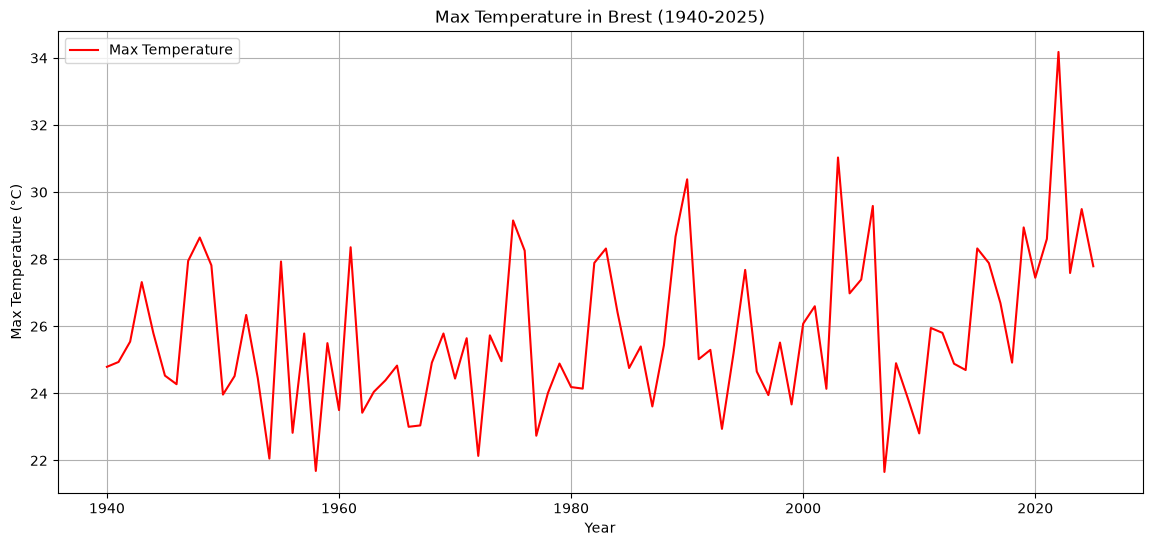

In [8]:
# annual maximum temperature in Brest
yearly_date=pd.to_datetime(yearly_temp_brest['valid_time'])
yearly_temp=pd.DataFrame({'year': yearly_date.dt.year, 'min': yearly_temp_brest['min'], 'max': yearly_temp_brest['max'], 'co2': yearly_temp_brest['co2']})
y=yearly_temp['max']
x=yearly_temp['year']
plt.figure(figsize=(14,6))
plt.plot(x, y, color='red', label='Max Temperature')
plt.xlabel('Year')
plt.ylabel('Max Temperature (°C)')
plt.title('Max Temperature in Brest (1940-2025)')
plt.grid(True)
plt.legend()
plt.show()


*Comment*:

The annual maximum of the air temperature in Brest varies between 21.7 and 34.2 °C (mean 25.8 °C, standard deviation 2.3 °C). The record is 34.2 °C in 2022, more than 3.5 standard deviations above the mean; only three years exceed 30 °C (1990, 2003 and 2022). There is a significant warming trend of about +0.3 °C per decade (mean of 25.1 °C in 1940-1969 against 26.5 °C in 1996-2025), but the year-to-year variability is much larger: the annual maximum is the single hottest hour of the year, so it is a very noisy variable.

## 2.2 Link between the annual maximum and CO₂

**Objective.** Quantify the correlation between the annual maximum temperature in Brest and the global annual CO₂, and test several transformations of both variables to increase the linear correlation coefficient.

### Linear correlation and transformations

The Pearson correlation between two series $U$ and $V$ is
$$r(U,V)=\frac{\sum_i (U_i-\bar U)(V_i-\bar V)}{\sqrt{\sum_i (U_i-\bar U)^2}\sqrt{\sum_i (V_i-\bar V)^2}}$$
It only measures a *linear* link. To improve it, we apply monotonic transformations $f$ and $g$ and compute $r\big(f(\text{Tmax}),g(\text{CO}_2)\big)$ with square root, logarithm and powers.

Correlation between max temperature and CO2 levels: 0.3143260373611496


C:\Users\AL ASDIQA\AppData\Local\Temp\ipykernel_27560\1118622935.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


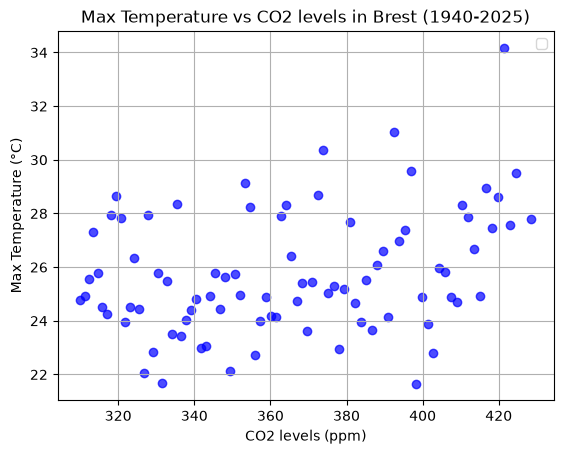

In [9]:
# linear correlation between Tmax and CO2 (no transformation)
max_temp_co2 = yearly_temp[['year', 'max', 'co2']]
correlation=max_temp_co2['max'].corr(max_temp_co2['co2'])
print(f"Correlation between max temperature and CO2 levels: {correlation}")
plt.scatter(max_temp_co2['co2'], max_temp_co2['max'], color='blue', alpha=0.7)
plt.xlabel('CO2 levels (ppm)')
plt.ylabel('Max Temperature (°C)')
plt.title('Max Temperature vs CO2 levels in Brest (1940-2025)')
plt.grid(True)
plt.legend()
plt.show()

In [10]:
max_temp=yearly_temp['max']
co2=yearly_temp['co2']
# transformation 1: square root on both variables
sqrt_max_temp=np.sqrt(max_temp)
correlation_sqrt=sqrt_max_temp.corr(np.sqrt(co2))
print(f"Correlation between sqrt of max temperature and sqrt of CO2 levels: {correlation_sqrt}")

# transformation 2: logarithm of Tmax
log_max_temp=np.log(max_temp)
log_co2=np.log(co2)
correlation_log=log_max_temp.corr(log_co2)
print(f"Correlation between log of max temperature and log of CO2 levels: {correlation_log}")

# transformation 3: high power of CO2 #still physically it doesn't make much sense since we deform heavily the data
max_temp_changed=max_temp
correlation_square=max_temp_changed.corr(co2**40)
print(f"Correlation between max temperature and CO2 to the power 40: {correlation_square}")

# transformation 4: 5-year rolling mean of Tmax + high powers
max_temp=yearly_temp['max'].rolling(5).mean()
max_temp=max_temp**18 
co2_poly = co2**26
correlation_poly=max_temp.corr(co2_poly)
print(f"Correlation between 5-year mean of Tmax (power 18) and CO2 (power 26): {correlation_poly}")


Correlation between sqrt of max temperature and sqrt of CO2 levels: 0.30621456129503144
Correlation between log of max temperature and log of CO2 levels: 0.2977579138473162
Correlation between max temperature and CO2 to the power 40: 0.40480828468173596
Correlation between 5-year mean of Tmax (power 18) and CO2 (power 26): 0.8081940842739984


### Polynomial regression

We fit $T_{max,t}=a+b\,c_t+d\,c_t^2+\varepsilon_t$ ($c_t$ = CO₂ in ppm) by least squares, and measure the quality with
$$R^2=1-\frac{\sum_t (T_{max,t}-\hat T_{max,t})^2}{\sum_t (T_{max,t}-\bar T_{max})^2}$$

In [11]:
# polynomial regression (degree 2) of Tmax on CO2
#Let's use machine learning to get the transformation on max_temp and co2 to get the best correlation
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

max_temp=yearly_temp['max']
co2=yearly_temp['co2']
X = co2.values.reshape(-1,1)
y = max_temp.values

poly = PolynomialFeatures(degree=2)

X_poly = poly.fit_transform(X)

model = LinearRegression()
model.fit(X_poly, y)

y_pred = model.predict(X_poly)

print(r2_score(y, y_pred))
a = model.intercept_
b = model.coef_[1]
c = model.coef_[2]
print(f"Tmax = {a:.4f} + {b:.4f}*CO2 + {c:.8f}*CO2²")
corr = np.corrcoef(y, y_pred)[0,1]

print("Correlation =", corr)

0.1615786433623827
Tmax = 91.3784 + -0.3818*CO2 + 0.00054876*CO2²
Correlation = 0.4019684606562845


### Neural network regression (deterministic)

A multilayer perceptron $T_{max}=f_\theta(c)$ with layers $1\rightarrow32\rightarrow64\rightarrow32\rightarrow1$ and ReLU activations. Both variables are standardised, $\tilde c=(c-\bar c)/s_c$ and $\tilde T=(T_{max}-\bar T)/s_T$, then the network is trained with the mean squared error
$$\mathcal L(\theta)=\frac1n\sum_t\big(\tilde T_t-f_\theta(\tilde c_t)\big)^2$$
using Adam (learning rate $10^{-3}$, 1000 full-batch iterations). Predictions are converted back to °C.

Entraînement sur : cpu
Epoch [100/1000], Loss: 0.8156
Epoch [200/1000], Loss: 0.7488
Epoch [300/1000], Loss: 0.7207
Epoch [400/1000], Loss: 0.6823
Epoch [500/1000], Loss: 0.6348
Epoch [600/1000], Loss: 0.5942
Epoch [700/1000], Loss: 0.5723
Epoch [800/1000], Loss: 0.5551
Epoch [900/1000], Loss: 0.5348
Epoch [1000/1000], Loss: 0.5206
Pour CO₂ = 420.0 ppm, Température prédite ≈ 29.84 °C


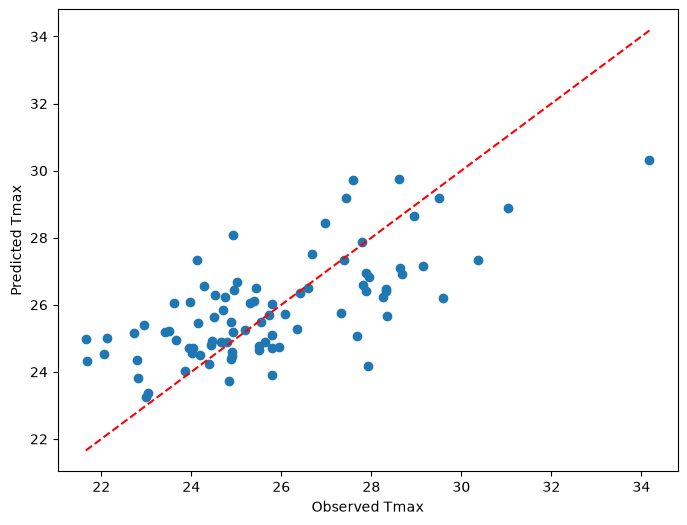

R² = 0.4773116265266222


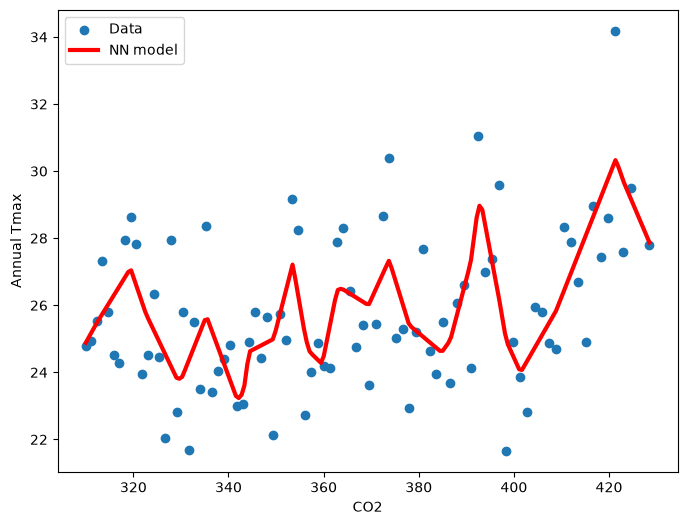

In [12]:
# neural network Tmax = f(CO2), deterministic version
import torch
import torch.nn as nn
import torch.optim as optim

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Entraînement sur : {device}")

# standardise inputs and outputs (with raw values the network underfits)
co2_mean, co2_std = co2.values.mean(), co2.values.std()
tmp_mean, tmp_std = max_temp.values.mean(), max_temp.values.std()

co2_tensor = torch.tensor((co2.values - co2_mean) / co2_std, dtype=torch.float32).view(-1, 1).to(device)
max_temp_tensor = torch.tensor((max_temp.values - tmp_mean) / tmp_std, dtype=torch.float32).view(-1, 1).to(device)

class TempCO2Model(nn.Module):
    def __init__(self):
        super(TempCO2Model, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 32),  # input layer
            nn.ReLU(),
            nn.Linear(32, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)   # output layer
        )

    def forward(self, x):
        return self.net(x)
    

def train_model(model, x_train, y_train, epochs=1000, lr=0.001):
        criterion = nn.MSELoss()
        optimizer = optim.Adam(model.parameters(), lr=lr)

        for epoch in range(epochs):
           model.train()
           outputs = model(x_train)
           loss = criterion(outputs, y_train)

           optimizer.zero_grad()
           loss.backward()
           optimizer.step()

           if (epoch + 1) % 100 == 0:
               print(f"Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}")

def predict(model, co2_value):
        model.eval()
        with torch.no_grad():
            co2_tensor = torch.tensor([[(co2_value - co2_mean) / co2_std]], dtype=torch.float32).to(device)
            prediction = model(co2_tensor)
        return prediction.item() * tmp_std + tmp_mean

if __name__ == "__main__":
    # data
    co2_tensor = torch.tensor((co2.values - co2_mean) / co2_std, dtype=torch.float32).view(-1, 1).to(device)
    max_temp_tensor = torch.tensor((max_temp.values - tmp_mean) / tmp_std, dtype=torch.float32).view(-1, 1).to(device)

    # model
    model = TempCO2Model().to(device)

    # training
    train_model(model, co2_tensor, max_temp_tensor)

    # test prediction
    test_co2 = 420.0
    predicted_temp = predict(model, test_co2)
    print(f"Pour CO₂ = {test_co2} ppm, Température prédite ≈ {predicted_temp:.2f} °C")

model.eval()

with torch.no_grad():
    y_pred = model(co2_tensor).cpu().numpy() * tmp_std + tmp_mean

plt.figure(figsize=(8,6))

plt.scatter(
    max_temp.values.reshape(-1, 1),
    y_pred
)

plt.plot(
    [max_temp.min(), max_temp.max()],
    [max_temp.min(), max_temp.max()],
    'r--'
)

plt.xlabel("Observed Tmax")
plt.ylabel("Predicted Tmax")

plt.show()

from sklearn.metrics import r2_score

r2 = r2_score(
    max_temp.values.reshape(-1, 1),
    y_pred
)

print("R² =", r2)

co2_range = np.linspace(
    co2.min(),
    co2.max(),
    200
)

with torch.no_grad():

    pred = model(
        torch.tensor(
            ((co2_range - co2_mean) / co2_std).reshape(-1,1),
            dtype=torch.float32
        ).to(device)
    )

pred = pred.cpu().numpy() * tmp_std + tmp_mean

plt.figure(figsize=(8,6))

plt.scatter(
    co2,
    max_temp,
    label="Data"
)

plt.plot(
    co2_range,
    pred,
    color="red",
    linewidth=3,
    label="NN model"
)

plt.xlabel("CO2")
plt.ylabel("Annual Tmax")

plt.legend()

plt.show()


*Comment*:

The linear correlation between Tmax and CO₂ is only 0.31 (so CO₂ alone explains about 10% of the variance). The square root and logarithm transformations do not improve it (0.31 and 0.30), a high power of CO₂ gives 0.40 and the degree-2 polynomial 0.40 ($R^2=0.16$). The correlation of 0.81 obtained with the 5-year mean of Tmax is misleading: the moving average removes most of the year-to-year noise (the 5-year mean alone already gives 0.49 with CO₂ without any power) and the successive values overlap, so it cannot be compared with the correlation on the annual maximum. In the first version, the neural network was trained on raw values (CO₂ around 300-430 ppm) and it underfitted (R² = -0.43, worse than predicting the mean), therefore both variables are now standardised. In the end, all these deterministic fits remain weak: CO₂ explains the slow trend of Tmax but not the interannual variability, which is dominated by natural variability. This is why we need a probabilistic approach.

## 2.3 Probabilistic forecasts under the SSP scenarios

**Objective.** Produce probabilistic (not deterministic) predictions of the annual maximum temperature until 2100, conditionally on the three main climate scenarios (SSPs), which differ in their level of annual CO₂ emissions. Four methods are presented and justified mathematically, then compared.

### Notation and general framework

- $Y_t$: annual maximum temperature in Brest (°C) in year $t$; $c_t$: global CO₂ concentration (ppm).
- Historical period: $t=1940,\dots,2025$. Future: $t=2026,\dots,2100$ with one CO₂ path $c^{(s)}_t$ per scenario $s\in\{$SSP1-2.6, SSP2-4.5, SSP5-8.5$\}$.

All methods below follow the same idea: learn a conditional distribution $p(Y_t\mid c_t)$ on the historical data, then draw $M=2000$ possible futures (Monte Carlo)
$$Y^{(m)}_t \sim p\big(Y_t\mid c^{(s)}_t\big),\qquad m=1,\dots,M$$
From the ensemble we get the quantiles $\hat q_{5\%}(t)$, $\hat q_{50\%}(t)$, $\hat q_{95\%}(t)$ and any probability of exceeding a threshold $\tau$:
$$\hat P(Y_t>\tau)=\frac1M\sum_{m=1}^{M}\mathbf 1\big[Y^{(m)}_t>\tau\big]$$
The four methods differ in the way $p(Y_t\mid c_t)$ is built.

### Future CO₂ scenarios

In [13]:
# future CO2 (ppm) for the three SSP scenarios, 2026-2100
# read data
yearly_future_co2 = pd.read_csv('yearly_future_co2.csv')
print(yearly_future_co2)

    valid_time    ssp1-2.6    ssp2-4.5    ssp5-8.5
0   2026-01-01  420.780225  420.188542  421.121677
1   2027-01-01  421.558613  423.729506  425.754016
2   2028-01-01  422.333331  427.165818  430.437310
3   2029-01-01  423.102552  430.500572  435.172120
4   2030-01-01  423.864459  433.736770  439.959014
..         ...         ...         ...         ...
70  2096-01-01  405.235885  525.328317  905.708594
71  2097-01-01  403.933331  525.761931  915.671389
72  2098-01-01  402.625279  526.182729  925.743774
73  2099-01-01  401.313558  526.591091  935.926955
74  2100-01-01  400.000000  526.987384  946.222152

[75 rows x 4 columns]


Monte Carlo pipeline:

```
Monte Carlo
      ↓
2000 possible futures
      ↓
distribution
      ↓
quantiles
      ↓
probabilities
      ↓
SSP curves until 2100
```

### Method A: neural network + MC Dropout

**Mathematical description**

Input: $x_t=\ln(c_t/c_{1940})$, then standardised with the training mean and standard deviation (same for the output $Y_t$). Using $\ln(\text{CO}_2)$ is physically motivated since the radiative forcing of CO₂ is approximately logarithmic.

The network outputs a mean and a log-variance (heteroscedastic Gaussian):
$$\mu_\theta(x)=g_\theta\big(\text{clip}(x)\big)_1+w\,x+b,\qquad \log\sigma^2_\theta(x)=g_\theta\big(\text{clip}(x)\big)_2$$
where $g_\theta$ is an MLP ($1\rightarrow64\rightarrow64\rightarrow2$, SiLU, dropout $p=0.2$), $\text{clip}$ restricts $x$ to the training range, and the linear skip connection $w\,x+b$ is the only part able to extrapolate to CO₂ values never seen (up to 950 ppm). It is trained by minimising the Gaussian negative log-likelihood
$$\mathcal L(\theta)=\frac1n\sum_t\left[\frac12\log\sigma^2_\theta(x_t)+\frac{(y_t-\mu_\theta(x_t))^2}{2\,\sigma^2_\theta(x_t)}\right]$$
with AdamW (3000 iterations).

**Sampling.** Dropout is kept active at inference (MC Dropout, Gal & Ghahramani 2016). For each of the $M$ passes, a different random mask $z^{(m)}$ is drawn and
$$y^{(m)}_t=\mu_{\theta,z^{(m)}}(x_t)+\sigma_{\theta,z^{(m)}}(x_t)\,\epsilon^{(m)}_t,\quad \epsilon^{(m)}_t\sim\mathcal N(0,1)$$
The dropout masks represent the model (epistemic) uncertainty and the Gaussian noise the natural (aleatoric) variability. Finally $Y^{(m)}_t=\sigma_Y\,y^{(m)}_t+\mu_Y$ (back to °C).

In [14]:
# Method A: neural network with MC Dropout (training + Monte Carlo sampling)
import numpy as np, pandas as pd, torch, torch.nn as nn

torch.manual_seed(0); np.random.seed(0)
hist = pd.read_csv('yearly_temp_brest.csv'); fut = pd.read_csv('yearly_future_co2.csv')
tmax, co2 = hist['max'].values, hist['co2'].values
ssps = list(fut.columns[1:])

# Input: x = ln(CO2/CO2_1940), standardised with training statistics
x_tr = np.log(co2 / co2[0]); mx, sx = x_tr.mean(), x_tr.std()
my, sy = tmax.mean(), tmax.std()
X = torch.tensor((x_tr - mx) / sx, dtype=torch.float32)[:, None]
Y = torch.tensor((tmax - my) / sy, dtype=torch.float32)[:, None]

XMIN, XMAX = X.min().item(), X.max().item()   # training range of the input

class MCDNet(nn.Module):
    """Heteroscedastic net: outputs mean and log-variance; dropout stays ON at inference (MC Dropout)."""
    def __init__(s, h=64, p=0.2):
        super().__init__()
        s.body = nn.Sequential(nn.Linear(1, h), nn.SiLU(), nn.Dropout(p),
                               nn.Linear(h, h), nn.SiLU(), nn.Dropout(p), nn.Linear(h, 2))
        s.skip = nn.Linear(1, 1)          # linear skip in ln(CO2): the only path that extrapolates
    def forward(s, x):
        o = s.body(x.clamp(XMIN, XMAX))   # body sees x clipped to the training range
        mu = o[:, :1] + s.skip(x); logv = o[:, 1:].clamp(-6, 3)
        return mu, logv

net = MCDNet(); opt = torch.optim.AdamW(net.parameters(), 3e-3, weight_decay=1e-2)
for _ in range(3000):                                       # Gaussian negative log-likelihood
    mu, logv = net(X)
    loss = (0.5 * logv + 0.5 * (Y - mu) ** 2 / logv.exp()).mean()
    opt.zero_grad(); loss.backward(); opt.step()

@torch.no_grad()
def mc_predict(co2_path, n_mc=2000):
    """n_mc stochastic forward passes (dropout active) + Gaussian aleatoric noise -> samples (n_mc, len(path))."""
    net.train()                                             # keep dropout active
    x = torch.tensor((np.log(co2_path / co2[0]) - mx) / sx, dtype=torch.float32)[:, None]
    out = []
    for _ in range(n_mc):
        mu, logv = net(x)
        out.append((mu + logv.exp().sqrt() * torch.randn_like(mu))[:, 0].numpy())
    return np.array(out) * sy + my

years = pd.to_datetime(fut.valid_time).dt.year.values
Y_ssp = {s: mc_predict(fut[s].values) for s in ssps}        # dict: SSP -> array (n_mc, 75 years)
for s in ssps:
    y = Y_ssp[s][:, -1]
    print(s, 'median %.1f | 5-95%%: %.1f-%.1f | P(>40°C) = %.2f %%' % (np.median(y), *np.percentile(y, [5, 95]), 100 * (y > 40).mean()))

ssp1-2.6 median 25.5 | 5-95%: 22.3-28.9 | P(>40°C) = 0.00 %
ssp2-4.5 median 30.7 | 5-95%: 25.8-36.6 | P(>40°C) = 1.00 %
ssp5-8.5 median 32.2 | 5-95%: 27.3-38.1 | P(>40°C) = 1.60 %


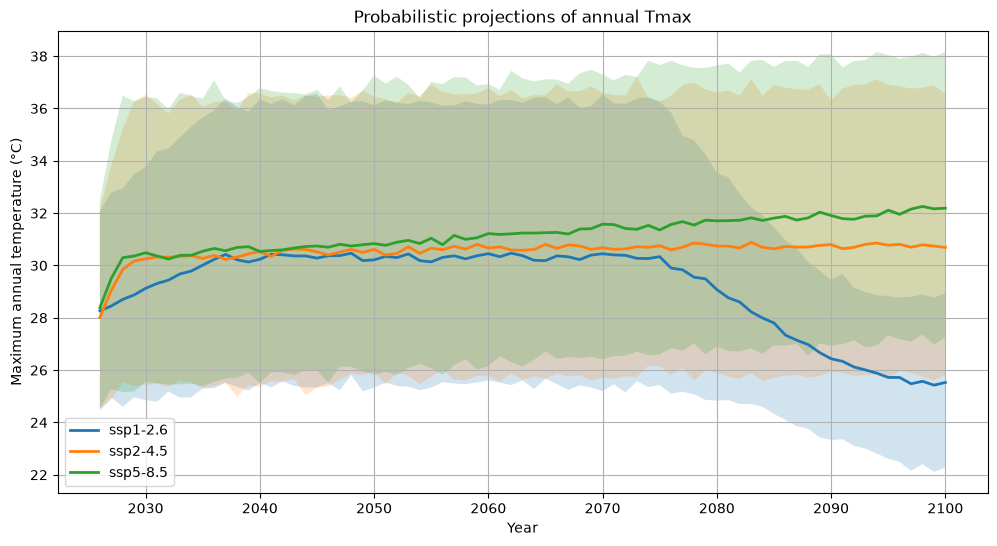

In [15]:
# median and 5%-95% envelope of the ensemble, for each SSP
plt.figure(figsize=(12,6))

for s in ssps:

    sims = Y_ssp[s]

    q05 = np.percentile(sims, 5, axis=0)
    q50 = np.percentile(sims, 50, axis=0)
    q95 = np.percentile(sims, 95, axis=0)

    plt.plot(
        years,
        q50,
        linewidth=2,
        label=s
    )

    plt.fill_between(
        years,
        q05,
        q95,
        alpha=0.2
    )

plt.xlabel("Year")
plt.ylabel("Maximum annual temperature (°C)")
plt.title("Probabilistic projections of annual Tmax")
plt.grid(True)
plt.legend()

plt.show()

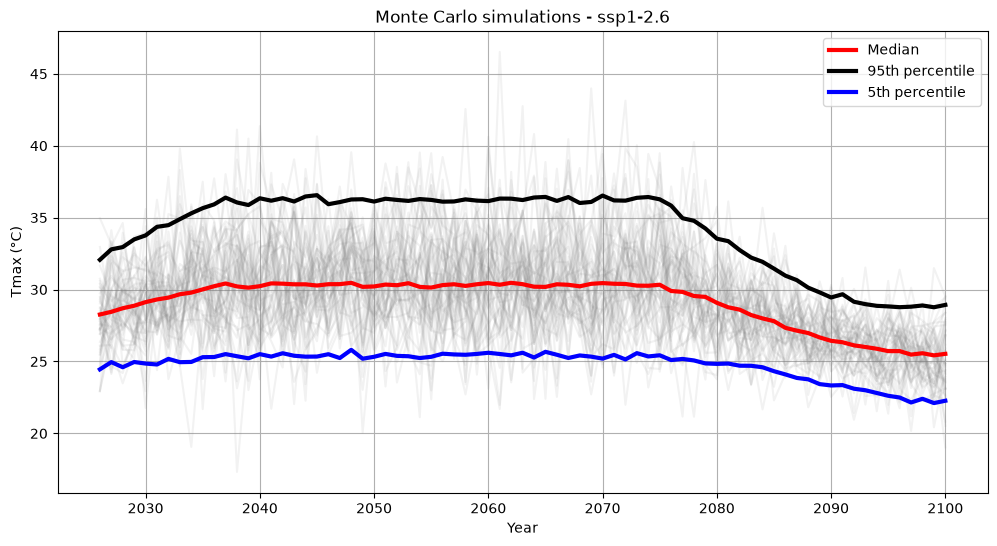

In [16]:
# 50 individual trajectories for the first scenario + quantiles
ssp = ssps[0]

plt.figure(figsize=(12,6))

for i in range(50):

    plt.plot(
        years,
        Y_ssp[ssp][i],
        alpha=0.1,
        color="grey"
    )

q50 = np.percentile(Y_ssp[ssp], 50, axis=0)
q05 = np.percentile(Y_ssp[ssp], 5, axis=0)
q95 = np.percentile(Y_ssp[ssp], 95, axis=0)

plt.plot(
    years,
    q50,
    color='red',
    linewidth=3,
    label='Median'
)

plt.plot(
    years,
    q95,
    color='black',
    linewidth=3,
    label='95th percentile'
)

plt.plot(
    years,
    q05,
    color='blue',
    linewidth=3,
    label='5th percentile'
)

plt.xlabel("Year")
plt.ylabel("Tmax (°C)")
plt.title(f"Monte Carlo simulations - {ssp}")

plt.legend()
plt.grid(True)

plt.show()

CO₂ path of the first scenario (SSP1-2.6), used as input for the trajectories above:

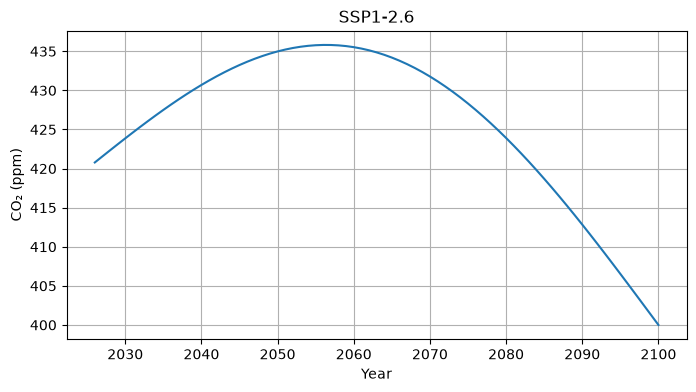

In [17]:
# CO2 path of the first scenario
plt.figure(figsize=(8,4))
plt.plot(years, fut['ssp1-2.6'])
plt.grid()
plt.xlabel("Year")
plt.ylabel("CO₂ (ppm)")
plt.title("SSP1-2.6")
plt.show()

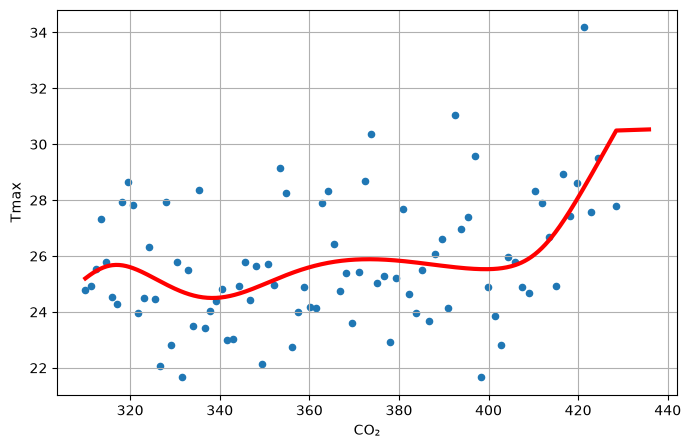

In [18]:
# CO2 -> Tmax curve learned by the network (mean prediction)
co2_range = np.linspace(
    co2.min(),
    fut['ssp1-2.6'].max(),
    500
)

x = torch.tensor(
    (np.log(co2_range/co2[0]) - mx)/sx,
    dtype=torch.float32
)[:,None]

net.eval()

with torch.no_grad():
    mu,_ = net(x)

mu = mu[:,0].numpy()*sy + my

plt.figure(figsize=(8,5))
plt.scatter(co2,max_temp,s=20)
plt.plot(co2_range,mu,'r',linewidth=3)
pred_nn=mu

plt.xlabel("CO₂")
plt.ylabel("Tmax")
plt.grid()
plt.show()

In [19]:
# keep the results of method A (the dictionary Y_ssp is overwritten by the next methods)
Y_A = Y_ssp
net.eval()
with torch.no_grad():
    mu_A = net(X)[0][:, 0].numpy() * sy + my   # mean fit on 1940-2025 (dropout off)

*Comment on method A*:

The network is flexible, so the fitted curve is not monotonic (it oscillates between 310 and 430 ppm) and it is almost flat above 430 ppm, where there is no data: the median is already about 30 °C around 2030 for SSP2-4.5 and SSP5-8.5, and the two scenarios stay close (30.7 and 32.2 °C in 2100). For SSP1-2.6, CO₂ goes back to 400 ppm and the median decreases after 2075 down to 25.5 °C, which is the level of the historical mean (25.8 °C). The ensemble is very wide (5-95% interval of 22-29 °C for SSP1-2.6, 26-37 °C for SSP2-4.5 and 27-38 °C for SSP5-8.5 in 2100) because it adds the dropout uncertainty to the natural variability. The separation between the scenarios is therefore partly an artefact of the shape of the curve.

### Method B: logarithmic regression + Monte Carlo

This time instead of neurons network+monte carlo, we'll try log regression+monte carlo

**Mathematical description**

$$Y_t=a+b\ln(c_t)+\varepsilon_t,\qquad \varepsilon_t\sim\mathcal N(0,\sigma^2)\ \text{i.i.d.}$$
$a$ and $b$ are estimated by ordinary least squares and $\sigma$ is the standard deviation of the historical residuals $\hat\varepsilon_t=Y_t-\hat a-\hat b\ln(c_t)$. For the future, each trajectory is
$$Y^{(m)}_t=\hat a+\hat b\ln\big(c^{(s)}_t\big)+\varepsilon^{(m)}_t,\qquad \varepsilon^{(m)}_t\sim\mathcal N(0,\hat\sigma^2)$$
This is the simplest baseline: the mean follows the CO₂ scenario and the spread is constant. The uncertainty on $a$ and $b$ is not included.

Tmax = -17.9046 + 7.4058 * log(CO2)
R² = 0.09224187390150695
Correlation = 0.3037134733618298


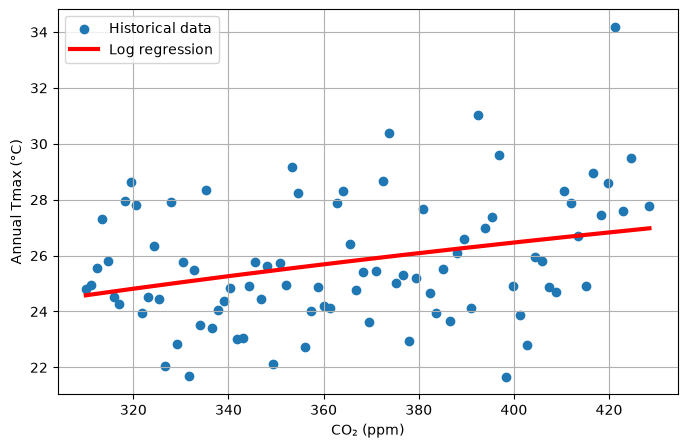

In [20]:
# Method B: Tmax = a + b*ln(CO2), fitted by least squares
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
max_temp=yearly_temp['max']
co2=yearly_temp['co2']
# variables
X = np.log(co2.values).reshape(-1, 1)
y = max_temp.values

# model
model = LinearRegression()
model.fit(X, y)

# predictions
y_pred = model.predict(X)

# coefficients
a = model.intercept_
b = model.coef_[0]

print(f"Tmax = {a:.4f} + {b:.4f} * log(CO2)")

# quality of the fit
r2 = r2_score(y, y_pred)
corr = np.corrcoef(y, y_pred)[0,1]

print("R² =", r2)
print("Correlation =", corr)

# plot
co2_range = np.linspace(co2.min(), co2.max(), 500)

pred_log = model.predict(
    np.log(co2_range).reshape(-1,1)
)

plt.figure(figsize=(8,5))

plt.scatter(
    co2,
    max_temp,
    label="Historical data"
)

plt.plot(
    co2_range,
    pred_log,
    color='red',
    linewidth=3,
    label='Log regression'
)

plt.xlabel("CO₂ (ppm)")
plt.ylabel("Annual Tmax (°C)")
plt.legend()
plt.grid()

plt.show()

Sigma = 2.161302874066578


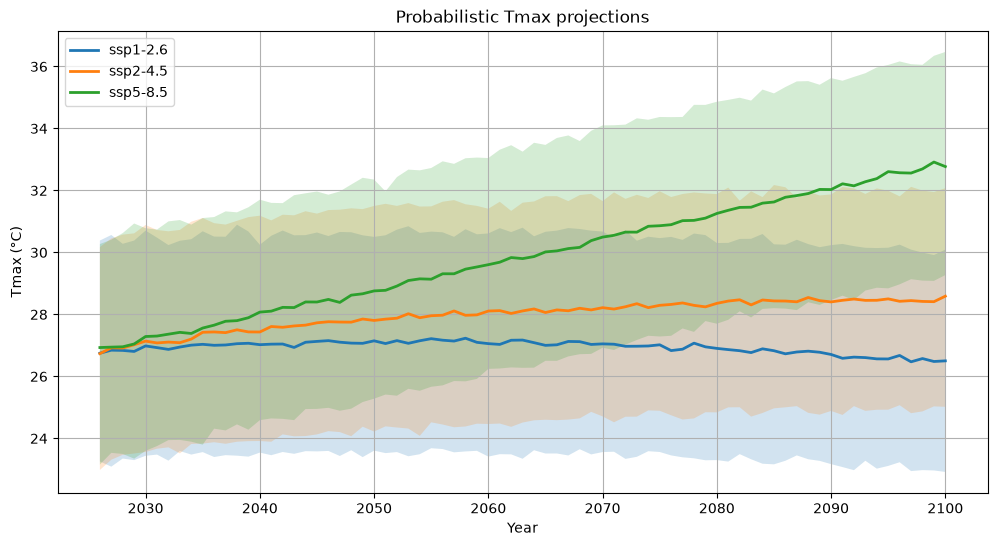

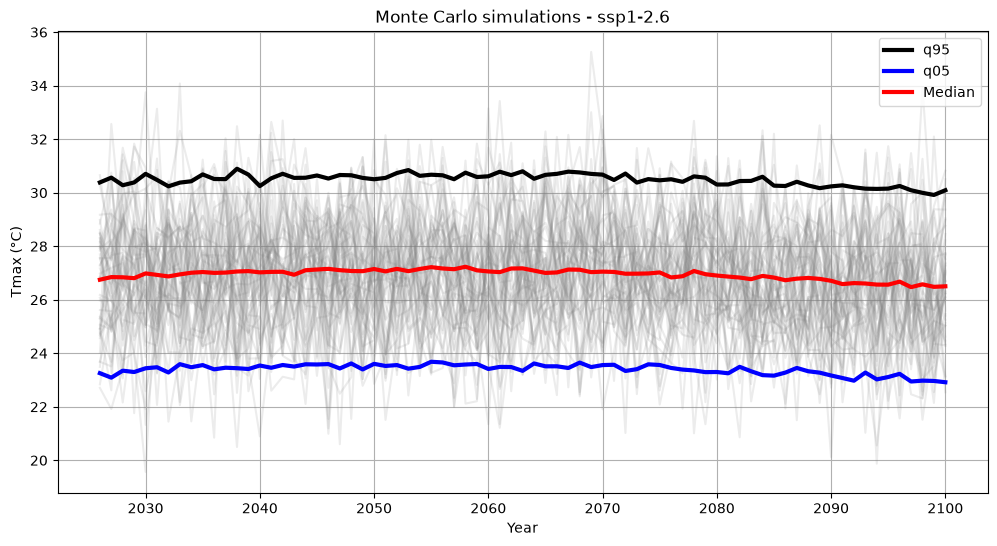

In [21]:
# historical residuals
residuals = y - y_pred

# standard deviation of the residuals
sigma = residuals.std()

print("Sigma =", sigma)

def mc_predict(co2_path, n_mc=2000):

    # mean prediction of the log model
    mu = model.predict(
        np.log(co2_path).reshape(-1,1)
    )

    simulations = []

    for _ in range(n_mc):

        noise = np.random.normal(
            0,
            sigma,
            len(mu)
        )

        simulations.append(mu + noise)

    return np.array(simulations)

# ensemble for each scenario
years = pd.to_datetime(fut["valid_time"]).dt.year.values

ssps = [
    "ssp1-2.6",
    "ssp2-4.5",
    "ssp5-8.5"
]

Y_ssp = {}

for ssp in ssps:

    Y_ssp[ssp] = mc_predict(
        fut[ssp].values,
        n_mc=2000
    )

plt.figure(figsize=(12,6))

for ssp in ssps:

    sims = Y_ssp[ssp]

    q05 = np.percentile(sims, 5, axis=0)
    q50 = np.percentile(sims, 50, axis=0)
    q95 = np.percentile(sims, 95, axis=0)

    plt.plot(
        years,
        q50,
        linewidth=2,
        label=ssp
    )

    plt.fill_between(
        years,
        q05,
        q95,
        alpha=0.2
    )

plt.xlabel("Year")
plt.ylabel("Tmax (°C)")
plt.title("Probabilistic Tmax projections")
plt.legend()
plt.grid()

plt.show()


### individual trajectories
ssp = "ssp1-2.6"

plt.figure(figsize=(12,6))

for i in range(50):

    plt.plot(
        years,
        Y_ssp[ssp][i],
        color='grey',
        alpha=0.15
    )

q50_monte = np.percentile(
    Y_ssp[ssp],
    50,
    axis=0
)

q95_monte=np.percentile(Y_ssp[ssp],95,axis=0)

q05_monte=np.percentile(Y_ssp[ssp],5,axis=0)

plt.plot(
    years,
    q95_monte,
    color='black',
    linewidth=3,
    label='q95'
)

plt.plot(
    years,
    q05_monte,
    color='blue',
    linewidth=3,
    label='q05'
)

plt.plot(
    years,
    q50_monte,
    color='red',
    linewidth=3,
    label='Median'
)

plt.xlabel("Year")
plt.ylabel("Tmax (°C)")
plt.title(f"Monte Carlo simulations - {ssp}")

plt.legend()
plt.grid()

plt.show()

In [22]:
# keep the results of method B
Y_B = Y_ssp
mu_B = y_pred   # mean fit on 1940-2025

*Comment on method B*:

The projections are smooth and monotonic in CO₂: in 2100 the median is 26.5 °C for SSP1-2.6, 28.5 °C for SSP2-4.5 and 32.8 °C for SSP5-8.5. The width of the 5-95% interval is constant (about ±3.6 °C, since $\sigma=2.16$ °C) and the scenarios only separate after 2050. This model is physically consistent (logarithmic effect of CO₂) but weak: the regression explains only 9% of the variance, and the uncertainty on $a$ and $b$ is ignored. Because of the Gaussian tail, extreme values are very rare: the probability of exceeding 40 °C in 2100 is about 0.05% for SSP5-8.5 (and practically 0 for the others), compared to 1.6% for method A.

### Method C: state space model + Monte Carlo

Let's try some other type of models: State Space Model + Monte Carlo.

The climate system exhibits temporal persistence and cannot be represented solely as a function of the instantaneous CO₂ concentration. Therefore, a State Space Model was employed, introducing a latent climate state that evolves through time and depends on the atmospheric CO₂ concentration. Future trajectories were generated through Monte Carlo simulations of the state dynamics under the SSP scenarios.

$h_{t+1}=ah_t+bCO2_t+w_t$

**Mathematical description of what is implemented**

*Step 1 – latent state.* A local-level state space model is fitted on the observed series with a Kalman filter, its two variances being learned with the EM algorithm:
$$h_{t+1}=h_t+w_t,\qquad Y_t=h_t+v_t,\qquad w_t\sim\mathcal N(0,Q),\ v_t\sim\mathcal N(0,R)$$
The filtered mean $\hat h_t$ is a smoothed version of the annual maximum (the "climate state").

*Step 2 – link with CO₂.* We regress the state on the CO₂ concentration: $\hat h_t=\alpha+\beta\ln(c_t)+\eta_t$, and $\sigma$ is the standard deviation of $\eta_t$.

*Step 3 – simulation.* With $\mu_t=\alpha+\beta\ln(c^{(s)}_t)$, the state follows an autoregression pulled towards $\mu_t$ (the weights $0.9$ and $0.1$ are fixed by hand, not estimated):
$$h^{(m)}_{t+1}=0.9\,h^{(m)}_t+0.1\,\mu_t+w^{(m)}_t,\qquad w^{(m)}_t\sim\mathcal N(0,\sigma^2)$$
The temporal persistence of the climate is therefore taken into account. Finally, the simulated annual maximum is the state plus the observation noise learned by the EM algorithm:
$$Y^{(m)}_t=h^{(m)}_t+v^{(m)}_t,\qquad v^{(m)}_t\sim\mathcal N(0,\hat R)$$

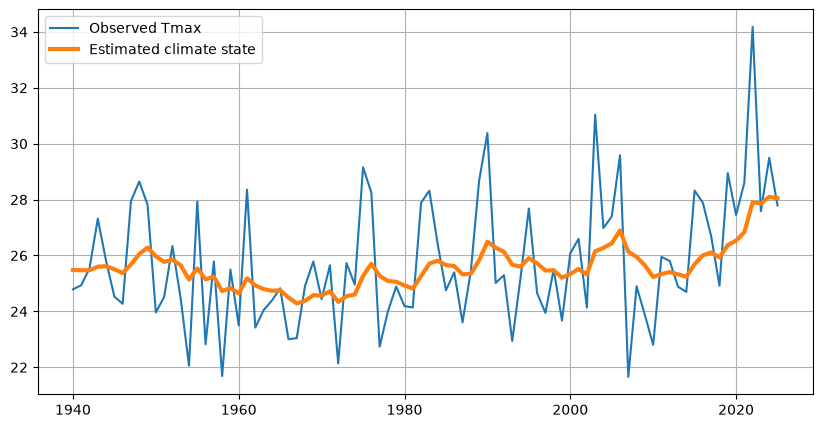

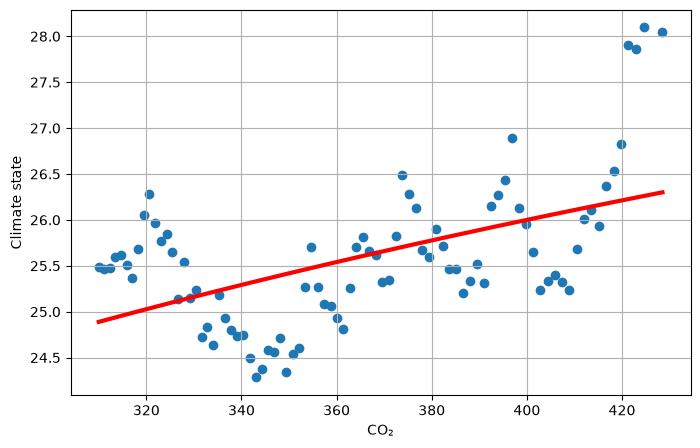

sigma = 0.6630564253952743


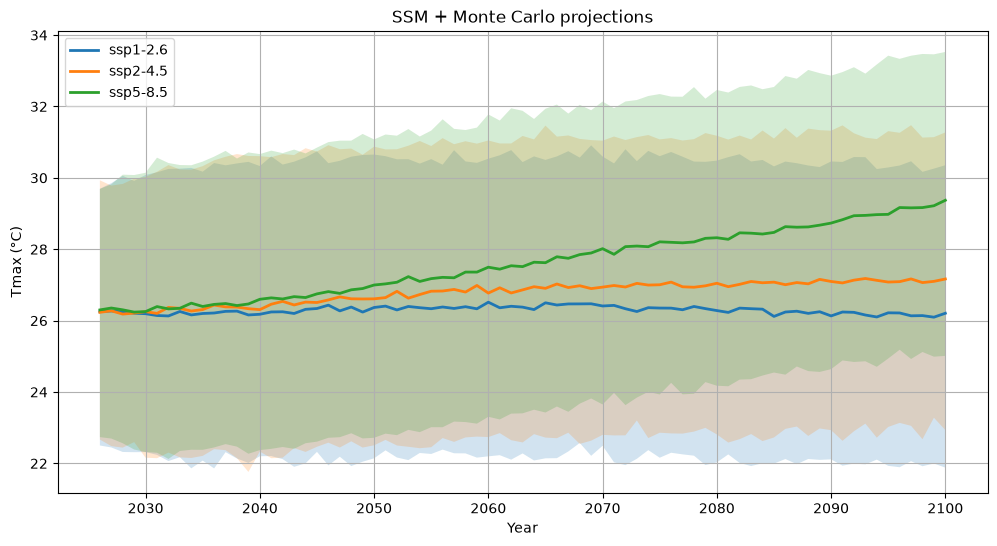

In [23]:
# Method C: Kalman filter to estimate the latent climate state, then Monte Carlo on the state
from pykalman import KalmanFilter

max_temp = yearly_temp['max'].values
co2 = yearly_temp['co2'].values
years_hist = yearly_temp['year'].values

#SSM model
kf = KalmanFilter(
    transition_matrices=[[1]],
    observation_matrices=[[1]],
    initial_state_mean=max_temp[0],
    observation_covariance=1,
    transition_covariance=1
)

# learn the parameters with the EM algorithm
kf = kf.em(
    max_temp,
    n_iter=100
)

# estimation of the hidden state
state_means, state_covs = kf.filter(max_temp)
#state_means[:,0] represents h_t 

plt.figure(figsize=(10,5))

plt.plot(
    years_hist,
    max_temp,
    label='Observed Tmax'
)

plt.plot(
    years_hist,
    state_means[:,0],
    linewidth=3,
    label='Estimated climate state'
)

plt.legend()
plt.grid()

plt.show()

#now we learn h_t=a+b*log(CO2)

from sklearn.linear_model import LinearRegression

X = np.log(co2).reshape(-1,1)

reg = LinearRegression()

reg.fit(
    X,
    state_means[:,0]
)

climate_pred = reg.predict(X)

plt.figure(figsize=(8,5))

plt.scatter(
    co2,
    state_means[:,0]
)

co2_range = np.linspace(
    co2.min(),
    co2.max(),
    500
)

plt.plot(
    co2_range,
    reg.predict(
        np.log(co2_range).reshape(-1,1)
    ),
    color='red',
    linewidth=3
)

plt.xlabel("CO₂")
plt.ylabel("Climate state")

plt.grid()

plt.show()

residuals = (
    state_means[:,0]
    - climate_pred
)

sigma = residuals.std()

print("sigma =", sigma)

years = pd.to_datetime(
    fut["valid_time"]
).dt.year.values

ssps = list(fut.columns[1:])

def mc_ssm(co2_future, n_mc=2000):

    mu = reg.predict(
        np.log(
            co2_future
        ).reshape(-1,1)
    )

    simulations = []

    for _ in range(n_mc):

        state = mu[0]

        trajectory = []

        for m in mu:

            state = (
                0.9*state
                + 0.1*m
                + np.random.normal(
                    0,
                    sigma
                )
            )

            # observed Tmax = latent state + observation noise (variance learned by EM)
            trajectory.append(
                state
                + np.random.normal(
                    0,
                    np.sqrt(np.asarray(kf.observation_covariance).item())
                )
            )

        simulations.append(
            trajectory
        )

    return np.array(
        simulations
    )

Y_ssp = {}

for ssp in ssps:

    Y_ssp[ssp] = mc_ssm(
        fut[ssp].values
    )

plt.figure(figsize=(12,6))

for ssp in ssps:

    sims = Y_ssp[ssp]

    q05 = np.percentile(
        sims,
        5,
        axis=0
    )

    q50 = np.percentile(
        sims,
        50,
        axis=0
    )

    q95 = np.percentile(
        sims,
        95,
        axis=0
    )

    plt.plot(
        years,
        q50,
        linewidth=2,
        label=ssp
    )

    plt.fill_between(
        years,
        q05,
        q95,
        alpha=0.2
    )

plt.xlabel("Year")
plt.ylabel("Tmax (°C)")
plt.title(
    "SSM + Monte Carlo projections"
)

plt.legend()
plt.grid()

plt.show()

In [24]:
# keep the results of method C
Y_C = Y_ssp
mu_C = climate_pred   # mean fit on 1940-2025 (CO2 regression of the state)

*Comment on method C*:

The latent state is much smoother than the observations, so the first version, which simulated only the state, produced an ensemble far too narrow (5-95% interval smaller than 5 °C, while the observed standard deviation is 2.3 °C). We now add the observation noise estimated by the EM algorithm. As in method B, the mean follows $\ln(\text{CO}_2)$, but the persistence term ($0.9\,h_t$) makes the state react slowly to the scenario: the three scenarios separate later than in method B.

### Method D: Transformer + Monte Carlo

now let's try a transformer

**Mathematical description**

The annual maximum is predicted from the $W=10$ previous years. After standardisation, the input is a sequence of $W$ vectors $x_i=(\tilde c_i,\tilde y_i)\in\mathbb R^2$ and the target is the next standardised maximum $\tilde y_{t+1}$ (the CO₂ of the target year is not part of the input).

Each vector is first embedded in dimension 16, $z_i=Ex_i+e$, and passed through one Transformer encoder layer with 2 attention heads, based on the self-attention
$$\text{Attention}(Q,K,V)=\text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$
Then the last token of the sequence goes through a linear layer to give the prediction $\hat y_{t+1}$. The training minimises the mean squared error with Adam (1000 iterations), and $\sigma$ is the standard deviation of the historical residuals.

**Forecast.** The model is applied recursively (autoregressive Monte Carlo): at each future year, the prediction is perturbed by a Gaussian noise $\mathcal N(0,\sigma^2)$ and added to the temperature history before predicting the next year. The CO₂ window also slides forward with the values of the scenario, so that the model always sees the CO₂ of the $W$ previous years, as in training.
$$\tilde y^{(m)}_{t+1}=F_\theta\big(\text{last }W\text{ values}\big)+\varepsilon^{(m)}_t,\qquad \varepsilon^{(m)}_t\sim\mathcal N(0,\sigma^2)$$

Epoch 200 Loss=0.2492
Epoch 400 Loss=0.2170
Epoch 600 Loss=0.1817
Epoch 800 Loss=0.2500
Epoch 1000 Loss=0.1133
[25.75783876]
[2.26845704]
R² = 0.8615249224137471
sigma = 0.8668437344240203
Forecasting ssp1-2.6
Forecasting ssp2-4.5
Forecasting ssp5-8.5


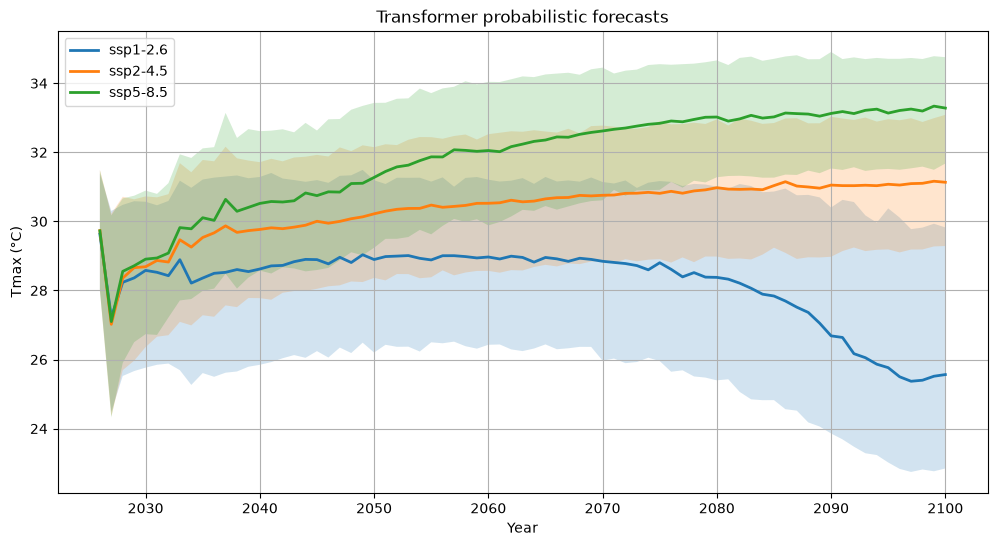

In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score

# DATA

max_temp = yearly_temp['max'].values
co2 = yearly_temp['co2'].values

# STANDARDISATION

scaler_x1 = StandardScaler()
scaler_x2 = StandardScaler()
scaler_y = StandardScaler()

co2_scaled = scaler_x1.fit_transform(
    co2.reshape(-1,1)
).flatten()

temp_scaled = scaler_y.fit_transform(
    max_temp.reshape(-1,1)
).flatten()

# Creation of sequences

window = 10

X = []
Y = []

for i in range(len(co2)-window):

    seq = np.column_stack([
        co2_scaled[i:i+window],
        temp_scaled[i:i+window]
    ])

    X.append(seq)

    Y.append(temp_scaled[i+window])

X = np.array(X)
Y = np.array(Y)

X = torch.tensor(
    X,
    dtype=torch.float32
)

Y = torch.tensor(
    Y,
    dtype=torch.float32
).unsqueeze(1)

# Transformer

class ClimateTransformer(nn.Module):

    def __init__(self):

        super().__init__()

        self.embedding = nn.Linear(
            2,
            16
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=16,
            nhead=2,
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=1
        )

        self.head = nn.Linear(
            16,
            1
        )

    def forward(self,x):

        x = self.embedding(x)

        x = self.transformer(x)

        x = x[:,-1,:]

        return self.head(x)

# Training

model = ClimateTransformer()

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3
)

for epoch in range(1000):

    pred = model(X)

    loss = criterion(
        pred,
        Y
    )

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    if (epoch+1)%200 == 0:

        print(
            f"Epoch {epoch+1}"
            f" Loss={loss.item():.4f}"
        )

# Historical fit

with torch.no_grad():

    pred_scaled = model(X).numpy()

print(scaler_y.mean_)
print(scaler_y.scale_)

pred_hist = scaler_y.inverse_transform(
    pred_scaled
).flatten()

true_hist = max_temp[window:]

print(
    "R² =",
    r2_score(
        true_hist,
        pred_hist
    )
)

# Residuals

residuals = true_hist - pred_hist

sigma = residuals.std()

print("sigma =", sigma)

# Future ssp forecast

def forecast_ssp(
        co2_future,
        n_mc=2000
):

    co2_future_scaled = scaler_x1.transform(
        co2_future.reshape(-1,1)
    ).flatten()

    temp_history = temp_scaled.tolist()

    simulations = []

    for sim in range(n_mc):

        simulated = []

        temp_current = temp_history.copy()

        co2_current = co2_scaled.tolist()   # CO2 history, extended with the scenario

        for c in co2_future_scaled:

            # CO2 of the previous `window` years (same inputs as in training)
            seq_co2 = np.array(co2_current[-window:])

            seq_temp = np.array(
                temp_current[-window:]
            )

            seq = np.column_stack([
                seq_co2,
                seq_temp
            ])

            seq = torch.tensor(
                seq,
                dtype=torch.float32
            ).unsqueeze(0)

            with torch.no_grad():

                pred = model(seq).item()

            pred += np.random.normal(
                0,
                sigma/scaler_y.scale_[0]
            )

            temp_current.append(pred)

            simulated.append(pred)

            co2_current.append(c)

        simulated = scaler_y.inverse_transform(
            np.array(simulated).reshape(-1,1)
        ).flatten()

        simulations.append(
            simulated
        )

    return np.array(simulations)

# SSPs

years = pd.to_datetime(
    fut['valid_time']
).dt.year.values

ssps = list(fut.columns[1:])

Y_ssp = {}

for ssp in ssps:

    print("Forecasting",ssp)

    Y_ssp[ssp] = forecast_ssp(
        fut[ssp].values,
        n_mc=1000
    )

# Plot

plt.figure(figsize=(12,6))

for ssp in ssps:

    sims = Y_ssp[ssp]

    q05 = np.percentile(
        sims,
        5,
        axis=0
    )

    q50 = np.percentile(
        sims,
        50,
        axis=0
    )

    q95 = np.percentile(
        sims,
        95,
        axis=0
    )

    plt.plot(
        years,
        q50,
        linewidth=2,
        label=ssp
    )

    plt.fill_between(
        years,
        q05,
        q95,
        alpha=0.2
    )

plt.xlabel("Year")
plt.ylabel("Tmax (°C)")
plt.title("Transformer probabilistic forecasts")
plt.legend()
plt.grid()

plt.show()

In [26]:
# keep the results of method D
Y_D = Y_ssp

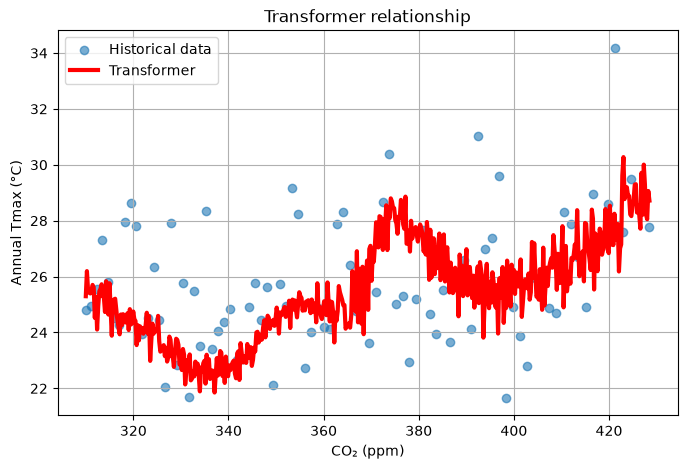

Transformer correlation = 0.9302183554663502


In [ ]:
# CO2 -> TMAX CURVE LEARNED BY THE TRANSFORMER

co2_range = np.linspace(
    co2.min(),
    co2.max(),
    500
)

temp_mean = np.mean(temp_scaled)

pred_curve = []

for c in co2_range:

    c_scaled = scaler_x1.transform(
        np.array([[c]])
    )[0,0]

    seq = np.column_stack([
        np.full(window, c_scaled),
        np.full(window, temp_mean)
    ])

    seq = torch.tensor(
        seq,
        dtype=torch.float32
    ).unsqueeze(0)

    with torch.no_grad():

        pred = model(seq).item()

    pred_curve.append(pred)

pred_curve = scaler_y.inverse_transform(
    np.array(pred_curve).reshape(-1,1)
).flatten()

plt.figure(figsize=(8,5))

plt.scatter(
    co2,
    max_temp,
    alpha=0.6,
    label="Historical data"
)

plt.plot(
    co2_range,
    pred_curve,
    color='red',
    linewidth=3,
    label='Transformer'
)

plt.xlabel("CO₂ (ppm)")
plt.ylabel("Annual Tmax (°C)")
plt.title("Transformer relationship")
plt.legend()
plt.grid()

plt.show()

corr_transformer = np.corrcoef(
    true_hist,
    pred_hist
)[0,1]

print(
    "Transformer correlation =",
    corr_transformer
)

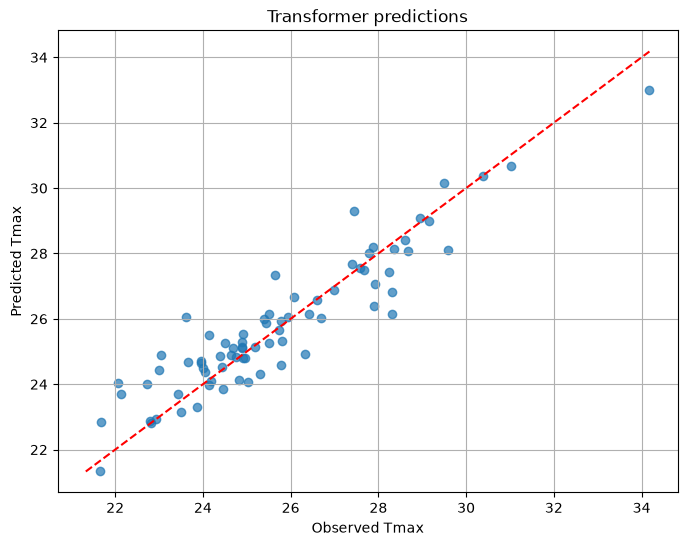

Correlation = 0.9302183554663502
R² = 0.8615249224137471


In [28]:
# transformer: predicted vs observed Tmax (historical period)
plt.figure(figsize=(8,6))

plt.scatter(
    true_hist,
    pred_hist,
    alpha=0.7
)

xmin = float(np.min([true_hist.min(), pred_hist.min()]))
xmax = float(np.max([true_hist.max(), pred_hist.max()]))
plt.plot(
    [xmin, xmax],
    [xmin, xmax],
    'r--'
)

plt.xlabel("Observed Tmax")
plt.ylabel("Predicted Tmax")
plt.title("Transformer predictions")

plt.grid()
plt.show()

corr_transformer = np.corrcoef(
    true_hist,
    pred_hist
)[0,1]

r2_transformer = r2_score(
    true_hist,
    pred_hist
)

print("Correlation =", corr_transformer)
print("R² =", r2_transformer)

*Comment on method D*:

The Transformer reaches an in-sample $R^2$ of 0.84, which is surprisingly high since the correlation between two successive annual maxima is only 0.23: this is overfitting (76 training sequences for a few thousand parameters). The consequence is that the residual standard deviation used for the noise ($\sigma=0.94$ °C) is much smaller than the real interannual variability (2.3 °C), so the ensemble is overconfident. Moreover, CO₂ values up to 950 ppm are far outside the training range (430 ppm), so the network cannot have learned their effect: the scenario separation should not be over-interpreted.

### Comparison of the methods

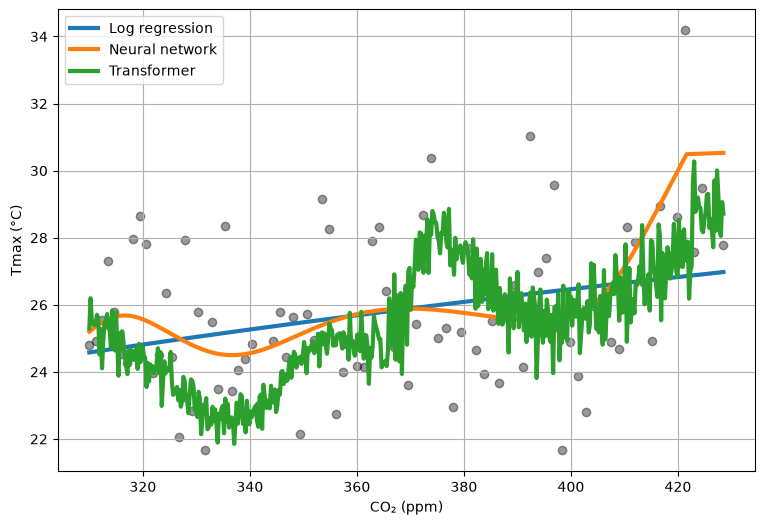

In [29]:
# comparison of the three fitted CO2 -> Tmax curves
plt.figure(figsize=(9,6))

plt.scatter(
    co2,
    max_temp,
    color='black',
    alpha=0.4
)

plt.plot(
    co2_range,
    pred_log,
    label='Log regression',
    linewidth=3
)

plt.plot(
    co2_range,
    pred_nn,
    label='Neural network',
    linewidth=3
)

plt.plot(
    co2_range,
    pred_curve,
    label='Transformer',
    linewidth=3
)

plt.xlabel("CO₂ (ppm)")
plt.ylabel("Tmax (°C)")
plt.legend()
plt.grid()

plt.show()

                   RMSE (°C)    R²
A: MC Dropout           1.99  0.23
B: log regression       2.16  0.09
C: state space          2.19  0.07
D: Transformer          0.87  0.86

           method scenario  median (°C)  5% (°C)  95% (°C)
    A: MC Dropout ssp1-2.6         25.5     22.3      28.9
    A: MC Dropout ssp2-4.5         30.7     25.8      36.6
    A: MC Dropout ssp5-8.5         32.2     27.3      38.1
B: log regression ssp1-2.6         26.5     22.9      30.1
B: log regression ssp2-4.5         28.6     25.0      32.1
B: log regression ssp5-8.5         32.8     29.3      36.5
   C: state space ssp1-2.6         26.2     21.9      30.4
   C: state space ssp2-4.5         27.2     22.9      31.3
   C: state space ssp5-8.5         29.4     25.0      33.5
   D: Transformer ssp1-2.6         25.6     22.8      29.8
   D: Transformer ssp2-4.5         31.1     29.3      33.1
   D: Transformer ssp5-8.5         33.3     31.7      34.8


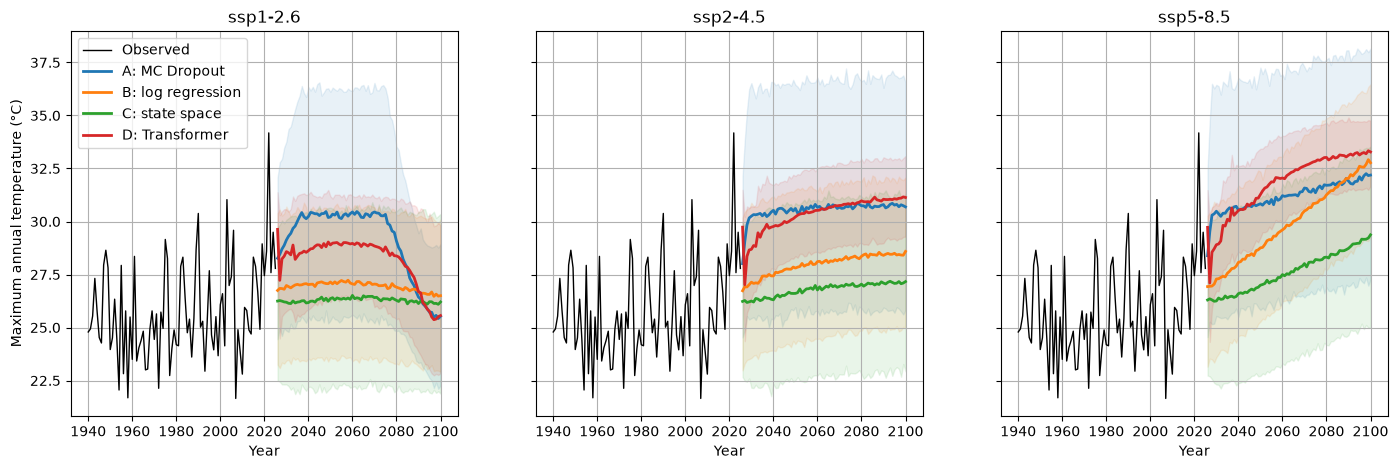

In [30]:
# Comparison of the four methods
from sklearn.metrics import r2_score

methods = {'A: MC Dropout': Y_A, 'B: log regression': Y_B, 'C: state space': Y_C, 'D: Transformer': Y_D}
colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']
obs = yearly_temp['max'].values

# 1) fit of the mean prediction on 1940-2025 (in-sample)
fits = {'A: MC Dropout': mu_A, 'B: log regression': mu_B, 'C: state space': mu_C}
scores = {}
for name, f in fits.items():
    scores[name] = [np.sqrt(np.mean((obs - f) ** 2)), r2_score(obs, f)]
# the transformer also uses the previous Tmax and starts in 1950
scores['D: Transformer'] = [np.sqrt(np.mean((true_hist - pred_hist) ** 2)), r2_score(true_hist, pred_hist)]
print(pd.DataFrame(scores, index=['RMSE (°C)', 'R²']).T.round(2))

# 2) projections in 2100: median and 5-95% interval
rows = []
for name, Y in methods.items():
    for s in ssps:
        z = Y[s][:, -1]
        rows.append([name, s, np.median(z), np.percentile(z, 5), np.percentile(z, 95)])
print()
print(pd.DataFrame(rows, columns=['method', 'scenario', 'median (°C)', '5% (°C)', '95% (°C)']).round(1).to_string(index=False))

# 3) median and 5-95% interval over time, one panel per scenario
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)
for ax, s in zip(axes, ssps):
    ax.plot(yearly_temp['year'], obs, color='black', linewidth=1, label='Observed')
    for (name, Y), col in zip(methods.items(), colors):
        ax.plot(years, np.median(Y[s], axis=0), color=col, linewidth=2, label=name)
        ax.fill_between(years, np.percentile(Y[s], 5, axis=0), np.percentile(Y[s], 95, axis=0), color=col, alpha=0.1)
    ax.set_title(s)
    ax.set_xlabel('Year')
    ax.grid(True)
axes[0].set_ylabel('Maximum annual temperature (°C)')
axes[0].legend()
plt.show()

*Comment*:

The scores on the historical period only measure the fit of the mean prediction (in-sample): they say nothing about the quality of the projections, and the Transformer score is not comparable with the others because it also uses the previous annual maxima. The real difference between the methods is the way they behave when CO₂ leaves the historical range (430 ppm up to 950 ppm). Methods A and D are neural networks that cannot extrapolate: beyond the training range their response is flat or unconstrained, so the separation between the scenarios depends on the architecture. Methods B and C impose a logarithmic link with CO₂, which is physically motivated, so the scenarios are ordered SSP1-2.6 < SSP2-4.5 < SSP5-8.5 and the warming continues with CO₂. For the probability of extremes, the width of the ensemble is also important: it is large for A (dropout) and smaller for the other methods, where it is controlled by the residual standard deviation. We consider B and C as the most reliable for extrapolation and A as the most flexible and the most uncertain.

## 2.4 Distribution in 2100 and probability of exceeding 40°C

**Objective.** From the probabilistic predictions, derive the distribution of the annual maximum temperature in 2100 for the three SSPs, and estimate the probability of exceeding 40 °C in Brest by 2100.

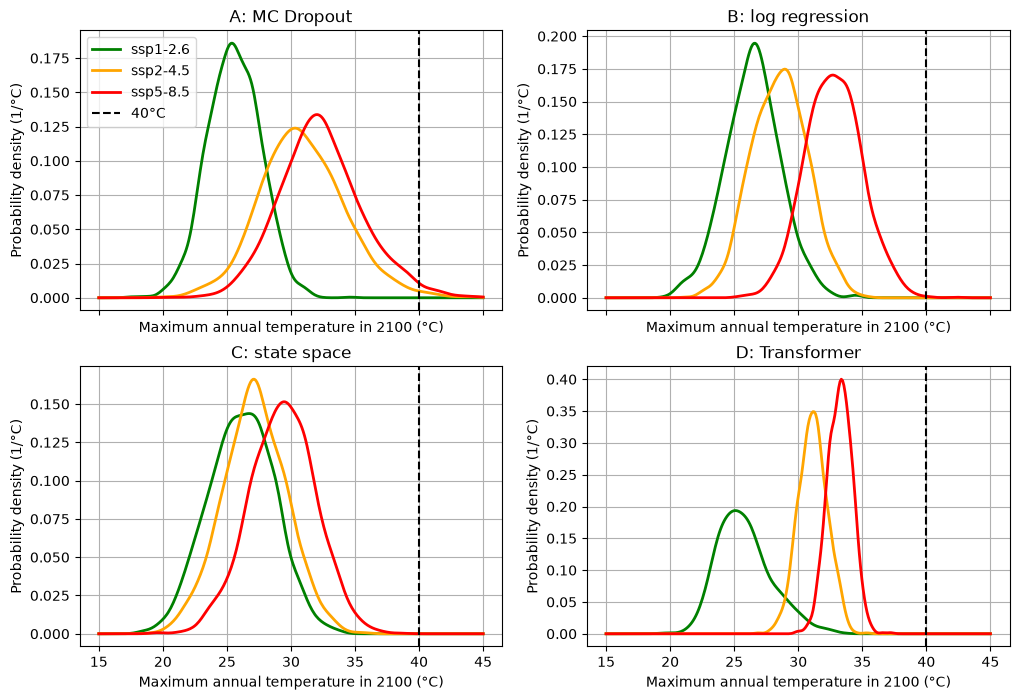

P(Tmax > 40°C in 2100), in %
          A: MC Dropout  B: log regression  C: state space  D: Transformer
ssp1-2.6            0.0                0.0             0.0             0.0
ssp2-4.5            1.0                0.0             0.0             0.0
ssp5-8.5            1.6                0.1             0.0             0.0


In [31]:
# distribution of the annual maximum in 2100 for each method and each scenario
from scipy.stats import gaussian_kde

scen_colors = {'ssp1-2.6': 'green', 'ssp2-4.5': 'orange', 'ssp5-8.5': 'red'}
grid = np.linspace(15, 45, 300)

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
for ax, (name, Y) in zip(axes.flat, methods.items()):
    for s in ssps:
        z = Y[s][:, -1]                      # last column = year 2100
        ax.plot(grid, gaussian_kde(z)(grid), color=scen_colors[s], linewidth=2, label=s)
    ax.axvline(40, color='black', linestyle='--', label='40°C')
    ax.set_title(name)
    ax.set_xlabel('Maximum annual temperature in 2100 (°C)')
    ax.set_ylabel('Probability density (1/°C)')
    ax.grid(True)
axes[0, 0].legend()
plt.show()

# probability of exceeding 40°C in 2100 (in %)
proba = {}
for name, Y in methods.items():
    proba[name] = [100 * (Y[s][:, -1] > 40).mean() for s in ssps]
print('P(Tmax > 40°C in 2100), in %')
print(pd.DataFrame(proba, index=ssps).round(2))

*Comment*:

In 2100 the whole distribution of the annual maximum shifts to higher values with the emissions, and its right tail becomes heavier for SSP5-8.5. However, 40 °C remains a very rare event: it is almost 6 °C above the record observed in Brest (34.2 °C in 2022). For method A the probability of exceeding 40 °C is 0.0% for SSP1-2.6, 1.0% for SSP2-4.5 and 1.6% for SSP5-8.5, and for method B it is about 0.05% for SSP5-8.5 and practically 0 for the other two. With 2000 members a probability below 0.05% is not resolved by the Monte Carlo simulation (it is displayed as 0), and the estimated values are very sensitive to the assumption on the tail (Gaussian noise in B, dropout in A). Our answer is therefore that exceeding 40 °C in Brest in 2100 is unlikely (a few percent at most) even in the worst scenario, but not impossible, and that the probability increases with the emissions.

## 2.5 Annual minimum temperatures

**Objective.** Repeat the study for the annual minimum temperature in Brest, with a different approach to generate the predictions.

For the annual minimum we use a different approach: a bootstrap Monte Carlo. We keep the logarithmic link with CO₂ but we do not assume Gaussian errors. At each of the 2000 draws we resample the historical years (with replacement) and refit the regression, which gives the uncertainty on the parameters, then we add a residual randomly drawn from the historical residuals, which keeps the asymmetry of the distribution (the annual minimum has a longer tail towards cold values). Instead of exceeding 40 °C, we look at two thresholds for the annual minimum in 2100: a severe cold year (below -5 °C) and a year without frost (above 0 °C).

In [32]:
# annual minimum: log regression + bootstrap Monte Carlo
from scipy.stats import gaussian_kde

tmin = yearly_temp['min'].values
x_hist = np.log(yearly_temp['co2'].values)
years_f = pd.to_datetime(fut['valid_time']).dt.year.values
rng = np.random.default_rng(0)

# least squares fit and empirical residuals (not assumed Gaussian)
coef = np.polyfit(x_hist, tmin, 1)
resid = tmin - np.polyval(coef, x_hist)
print(f"Tmin = {coef[1]:.2f} + {coef[0]:.2f} * ln(CO2), residual std = {resid.std():.2f} °C, corr = {np.corrcoef(x_hist, tmin)[0, 1]:.2f}")

M = 2000
Ymin_ssp = {}
for s in ssps:
    x_fut = np.log(fut[s].values)
    sims = np.empty((M, len(x_fut)))
    for m in range(M):
        idx = rng.integers(0, len(x_hist), len(x_hist))     # resample the years
        c = np.polyfit(x_hist[idx], tmin[idx], 1)           # refit: uncertainty on the parameters
        sims[m] = np.polyval(c, x_fut) + rng.choice(resid, len(x_fut))   # + resampled residual
    Ymin_ssp[s] = sims

Tmin = -18.45 + 3.01 * ln(CO2), residual std = 1.89 °C, corr = 0.15


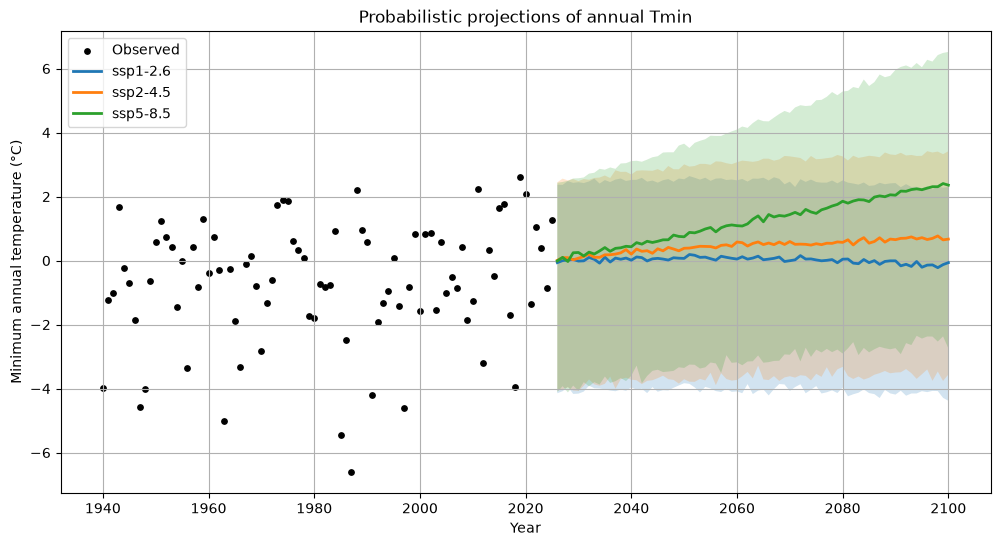

In [33]:
# projections of the annual minimum
plt.figure(figsize=(12, 6))
plt.scatter(yearly_temp['year'], tmin, color='black', s=15, label='Observed')
for s in ssps:
    sims = Ymin_ssp[s]
    plt.plot(years_f, np.percentile(sims, 50, axis=0), linewidth=2, label=s)
    plt.fill_between(years_f, np.percentile(sims, 5, axis=0), np.percentile(sims, 95, axis=0), alpha=0.2)
plt.xlabel("Year")
plt.ylabel("Minimum annual temperature (°C)")
plt.title("Probabilistic projections of annual Tmin")
plt.grid(True)
plt.legend()
plt.show()

ssp1-2.6 median -0.1 °C | 5-95%: -4.4 to 2.3 °C | P(Tmin < -5°C) = 2.6 % | P(Tmin > 0°C) = 48.9 %
ssp2-4.5 median 0.7 °C | 5-95%: -3.6 to 3.4 °C | P(Tmin < -5°C) = 1.2 % | P(Tmin > 0°C) = 62.8 %
ssp5-8.5 median 2.4 °C | 5-95%: -2.7 to 6.5 °C | P(Tmin < -5°C) = 0.6 % | P(Tmin > 0°C) = 79.8 %
observed 1940-2025: P(Tmin < -5°C) = 3.5 % | P(Tmin > 0°C) = 39.5 %


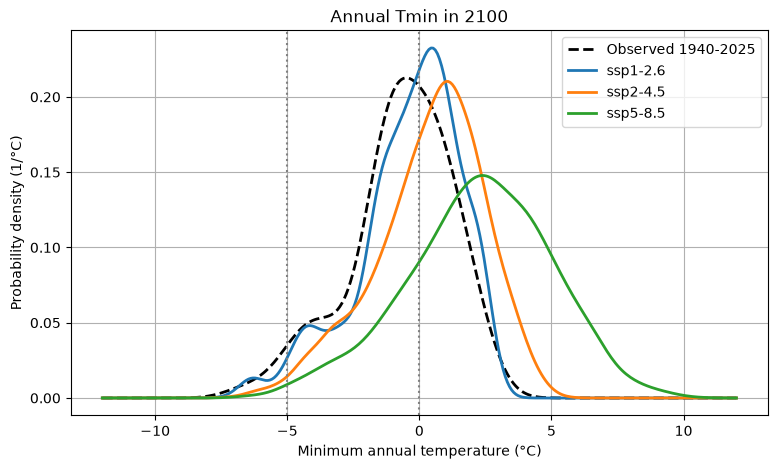

In [34]:
# distribution in 2100 and probabilities of a cold year / a year without frost
grid = np.linspace(-12, 12, 300)
plt.figure(figsize=(9, 5))
plt.plot(grid, gaussian_kde(tmin)(grid), 'k--', linewidth=2, label='Observed 1940-2025')
for s in ssps:
    z = Ymin_ssp[s][:, -1]
    plt.plot(grid, gaussian_kde(z)(grid), linewidth=2, label=s)
    print(s, 'median %.1f °C | 5-95%%: %.1f to %.1f °C | P(Tmin < -5°C) = %.1f %% | P(Tmin > 0°C) = %.1f %%'
          % (np.median(z), *np.percentile(z, [5, 95]), 100 * (z < -5).mean(), 100 * (z > 0).mean()))
print('observed 1940-2025: P(Tmin < -5°C) = %.1f %% | P(Tmin > 0°C) = %.1f %%' % (100 * (tmin < -5).mean(), 100 * (tmin > 0).mean()))
plt.axvline(-5, color='grey', linestyle=':')
plt.axvline(0, color='grey', linestyle=':')
plt.xlabel("Minimum annual temperature (°C)")
plt.ylabel("Probability density (1/°C)")
plt.title("Annual Tmin in 2100")
plt.grid(True)
plt.legend()
plt.show()

*Comment*:

The link between the annual minimum and CO₂ is much weaker than for the maximum (correlation of 0.15, slope not significant with a p-value of 0.18), and the residual standard deviation is large (1.9 °C). The projections show a slow warming of the coldest night of the year: the median in 2100 goes from -0.7 °C (observed mean) to -0.1 °C for SSP1-2.6, 0.7 °C for SSP2-4.5 and 2.4 °C for SSP5-8.5. The bootstrap makes the ensemble wider for SSP5-8.5 (5-95% interval from -2.7 to 6.5 °C) because the extrapolation to 950 ppm amplifies the uncertainty on the slope. Concerning the thresholds, years with a minimum below -5 °C are rare (3.5% of the years observed between 1940 and 2025) and become even rarer with the emissions (2.6%, 1.2% and 0.6% in 2100), while the probability of a year without any frost (minimum above 0 °C) increases from 40% in the observations to 49%, 63% and 80%. Since the trend is not significant, these numbers must be interpreted with care: they mostly reflect the assumed logarithmic link.